In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("⚠️ GPU not available")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
!pip install -q opencv-python matplotlib seaborn scikit-learn pillow grad-cam


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [3]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from PIL import Image

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()

Saving NEU_DET_1200_images_200_per_class.zip to NEU_DET_1200_images_200_per_class.zip


In [5]:
import os

print(os.listdir("/content"))

['.config', 'NEU_DET_1200_images_200_per_class.zip', 'sample_data']


In [6]:
import zipfile
import os

zip_files = [f for f in os.listdir("/content") if f.endswith(".zip")]

print("ZIP files found:")
for f in zip_files:
    print(f)

ZIP files found:
NEU_DET_1200_images_200_per_class.zip


In [7]:
zip_path = "/content/" + zip_files[0]

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    files_in_zip = zip_ref.namelist()

print("Number of files:", len(files_in_zip))
print("\nFirst 20 files:")
for f in files_in_zip[:20]:
    print(f)

Number of files: 2400

First 20 files:
NEU-DET/train/annotations/crazing_1.xml
NEU-DET/train/annotations/crazing_100.xml
NEU-DET/train/annotations/crazing_101.xml
NEU-DET/train/annotations/crazing_102.xml
NEU-DET/train/annotations/crazing_103.xml
NEU-DET/train/annotations/crazing_107.xml
NEU-DET/train/annotations/crazing_108.xml
NEU-DET/train/annotations/crazing_11.xml
NEU-DET/train/annotations/crazing_110.xml
NEU-DET/train/annotations/crazing_111.xml
NEU-DET/train/annotations/crazing_112.xml
NEU-DET/train/annotations/crazing_113.xml
NEU-DET/train/annotations/crazing_115.xml
NEU-DET/train/annotations/crazing_116.xml
NEU-DET/train/annotations/crazing_118.xml
NEU-DET/train/annotations/crazing_123.xml
NEU-DET/train/annotations/crazing_125.xml
NEU-DET/train/annotations/crazing_126.xml
NEU-DET/train/annotations/crazing_128.xml
NEU-DET/train/annotations/crazing_129.xml


In [8]:
import os

zip_files = [f for f in os.listdir("/content") if f.endswith(".zip")]

print("ZIP files:")
for f in zip_files:
    print(f)

ZIP files:
NEU_DET_1200_images_200_per_class.zip


In [9]:
import zipfile
import os

zip_path = "/content/" + zip_files[0]
extract_path = "/content/NEU_dataset"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [10]:
for root, dirs, files in os.walk(extract_path):
    print(root, "| Files:", len(files))

/content/NEU_dataset | Files: 0
/content/NEU_dataset/NEU-DET | Files: 0
/content/NEU_dataset/NEU-DET/train | Files: 0
/content/NEU_dataset/NEU-DET/train/images | Files: 0
/content/NEU_dataset/NEU-DET/train/images/scratches | Files: 160
/content/NEU_dataset/NEU-DET/train/images/crazing | Files: 160
/content/NEU_dataset/NEU-DET/train/images/pitted_surface | Files: 160
/content/NEU_dataset/NEU-DET/train/images/inclusion | Files: 160
/content/NEU_dataset/NEU-DET/train/images/patches | Files: 160
/content/NEU_dataset/NEU-DET/train/images/rolled-in_scale | Files: 160
/content/NEU_dataset/NEU-DET/train/annotations | Files: 959
/content/NEU_dataset/NEU-DET/validation | Files: 0
/content/NEU_dataset/NEU-DET/validation/images | Files: 0
/content/NEU_dataset/NEU-DET/validation/images/scratches | Files: 40
/content/NEU_dataset/NEU-DET/validation/images/crazing | Files: 40
/content/NEU_dataset/NEU-DET/validation/images/pitted_surface | Files: 40
/content/NEU_dataset/NEU-DET/validation/images/inclus

In [11]:
image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total images found:", len(image_files))

print("\nFirst 10 images:")
for img in image_files[:10]:
    print(img)

Total images found: 1200

First 10 images:
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_212.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_115.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_144.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_28.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_64.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_166.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_15.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_192.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_168.jpg
/content/NEU_dataset/NEU-DET/train/images/scratches/scratches_65.jpg


In [12]:
from collections import Counter
import os

folders = []

for root, dirs, files in os.walk(extract_path):
    image_count = sum(
        file.lower().endswith(image_extensions)
        for file in files
    )

    if image_count > 0:
        folders.append((root, image_count))

for folder, count in folders:
    print(folder, "→", count, "images")

/content/NEU_dataset/NEU-DET/train/images/scratches → 160 images
/content/NEU_dataset/NEU-DET/train/images/crazing → 160 images
/content/NEU_dataset/NEU-DET/train/images/pitted_surface → 160 images
/content/NEU_dataset/NEU-DET/train/images/inclusion → 160 images
/content/NEU_dataset/NEU-DET/train/images/patches → 160 images
/content/NEU_dataset/NEU-DET/train/images/rolled-in_scale → 160 images
/content/NEU_dataset/NEU-DET/validation/images/scratches → 40 images
/content/NEU_dataset/NEU-DET/validation/images/crazing → 40 images
/content/NEU_dataset/NEU-DET/validation/images/pitted_surface → 40 images
/content/NEU_dataset/NEU-DET/validation/images/inclusion → 40 images
/content/NEU_dataset/NEU-DET/validation/images/patches → 40 images
/content/NEU_dataset/NEU-DET/validation/images/rolled-in_scale → 40 images


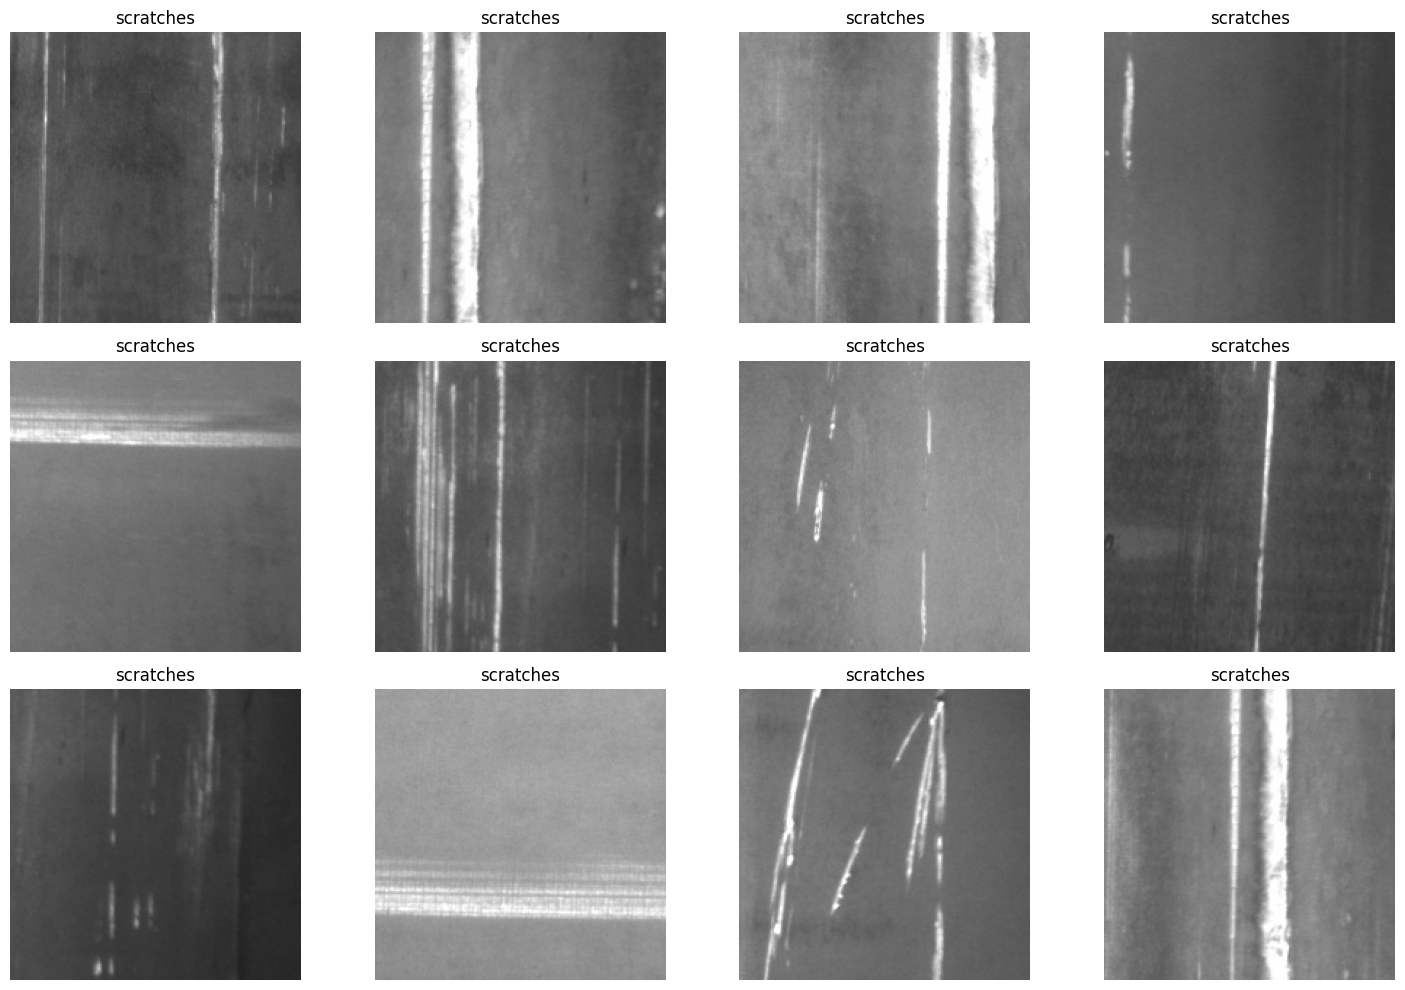

In [13]:
from PIL import Image
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 10))

for i, image_path in enumerate(image_files[:12]):
    img = Image.open(image_path)

    plt.subplot(3, 4, i + 1)
    plt.imshow(img, cmap="gray")
    plt.title(os.path.basename(os.path.dirname(image_path)))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
from PIL import Image
from collections import Counter

sizes = []

for image_path in image_files:
    with Image.open(image_path) as img:
        sizes.append(img.size)

print("Most common image sizes:")
print(Counter(sizes).most_common(10))

Most common image sizes:
[((200, 200), 1200)]


In [15]:
import os

print(os.listdir("/content"))

['.config', 'NEU_dataset', 'NEU_DET_1200_images_200_per_class.zip', 'sample_data']


In [16]:
import os

extract_path = "/content/NEU_dataset"

image_extensions = (".jpg", ".jpeg", ".png", ".bmp")

image_files = []

for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith(image_extensions):
            image_files.append(os.path.join(root, file))

print("Total images:", len(image_files))

Total images: 1200


In [17]:
for root, dirs, files in os.walk(extract_path):
    image_count = sum(
        f.lower().endswith(image_extensions)
        for f in files
    )

    if image_count > 0:
        print(root)
        print("Images:", image_count)
        print("-" * 50)

/content/NEU_dataset/NEU-DET/train/images/scratches
Images: 160
--------------------------------------------------
/content/NEU_dataset/NEU-DET/train/images/crazing
Images: 160
--------------------------------------------------
/content/NEU_dataset/NEU-DET/train/images/pitted_surface
Images: 160
--------------------------------------------------
/content/NEU_dataset/NEU-DET/train/images/inclusion
Images: 160
--------------------------------------------------
/content/NEU_dataset/NEU-DET/train/images/patches
Images: 160
--------------------------------------------------
/content/NEU_dataset/NEU-DET/train/images/rolled-in_scale
Images: 160
--------------------------------------------------
/content/NEU_dataset/NEU-DET/validation/images/scratches
Images: 40
--------------------------------------------------
/content/NEU_dataset/NEU-DET/validation/images/crazing
Images: 40
--------------------------------------------------
/content/NEU_dataset/NEU-DET/validation/images/pitted_surface
Image

In [18]:
from collections import Counter
import os

class_names = []

for path in image_files:
    folder = os.path.basename(os.path.dirname(path))
    class_names.append(folder)

class_counts = Counter(class_names)

print("Classes:")
for class_name, count in class_counts.items():
    print(f"{class_name}: {count}")

Classes:
scratches: 200
crazing: 200
pitted_surface: 200
inclusion: 200
patches: 200
rolled-in_scale: 200


In [19]:
import os

extract_path = "/content/NEU_dataset"

for root, dirs, files in os.walk(extract_path):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    if image_files:
        print("Folder:", root)
        print("Images:", len(image_files))
        print("Sample:", image_files[:5])
        print("-" * 50)

Folder: /content/NEU_dataset/NEU-DET/train/images/scratches
Images: 160
Sample: ['scratches_212.jpg', 'scratches_115.jpg', 'scratches_144.jpg', 'scratches_28.jpg', 'scratches_64.jpg']
--------------------------------------------------
Folder: /content/NEU_dataset/NEU-DET/train/images/crazing
Images: 160
Sample: ['crazing_71.jpg', 'crazing_214.jpg', 'crazing_86.jpg', 'crazing_236.jpg', 'crazing_128.jpg']
--------------------------------------------------
Folder: /content/NEU_dataset/NEU-DET/train/images/pitted_surface
Images: 160
Sample: ['pitted_surface_213.jpg', 'pitted_surface_136.jpg', 'pitted_surface_93.jpg', 'pitted_surface_225.jpg', 'pitted_surface_196.jpg']
--------------------------------------------------
Folder: /content/NEU_dataset/NEU-DET/train/images/inclusion
Images: 160
Sample: ['inclusion_151.jpg', 'inclusion_213.jpg', 'inclusion_96.jpg', 'inclusion_19.jpg', 'inclusion_201.jpg']
--------------------------------------------------
Folder: /content/NEU_dataset/NEU-DET/trai

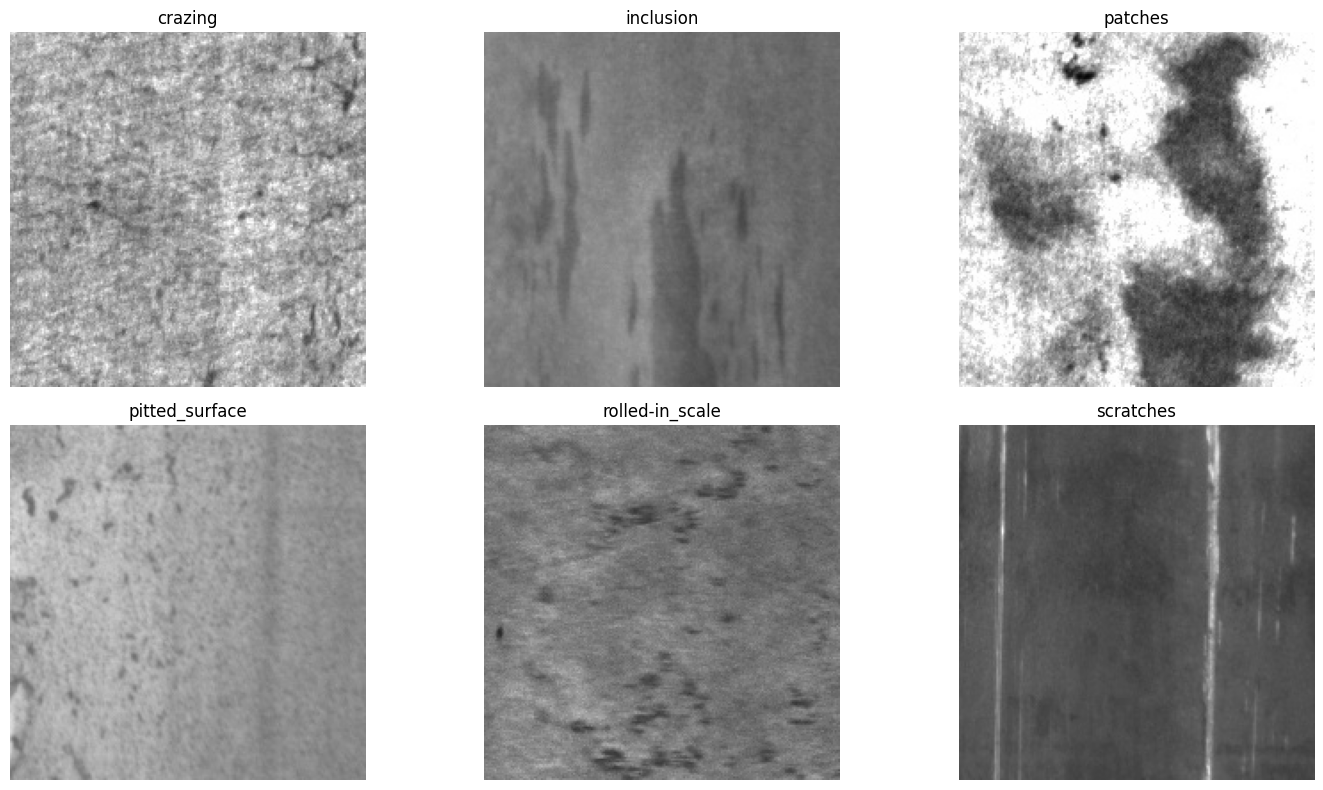

In [20]:
import os
import matplotlib.pyplot as plt
from PIL import Image

train_path = "/content/NEU_dataset/NEU-DET/train/images"

classes = [
    "crazing",
    "inclusion",
    "patches",
    "pitted_surface",
    "rolled-in_scale",
    "scratches"
]

plt.figure(figsize=(15, 8))

for i, class_name in enumerate(classes):
    class_path = os.path.join(train_path, class_name)
    image_name = os.listdir(class_path)[0]
    image_path = os.path.join(class_path, image_name)

    image = Image.open(image_path)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image, cmap="gray")
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [21]:
dimensions = []

for class_name in classes:
    class_path = os.path.join(train_path, class_name)

    for image_name in os.listdir(class_path):
        image_path = os.path.join(class_path, image_name)

        with Image.open(image_path) as image:
            dimensions.append(image.size)

print("Number of images:", len(dimensions))
print("First 10 dimensions:", dimensions[:10])

Number of images: 960
First 10 dimensions: [(200, 200), (200, 200), (200, 200), (200, 200), (200, 200), (200, 200), (200, 200), (200, 200), (200, 200), (200, 200)]


In [22]:
import torch
from torchvision import transforms

IMG_SIZE = 224

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Preprocessing created successfully!")

Preprocessing created successfully!


In [23]:
from torchvision.datasets import ImageFolder

train_dataset = ImageFolder(
    "/content/NEU_dataset/NEU-DET/train/images",
    transform=train_transform
)

val_dataset = ImageFolder(
    "/content/NEU_dataset/NEU-DET/validation/images",
    transform=val_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Classes:", train_dataset.classes)

Training images: 960
Validation images: 240
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [24]:
from torch.utils.data import DataLoader

BATCH_SIZE = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2
)

print("DataLoaders created!")

DataLoaders created!


In [25]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Labels:", labels[:10])

Image batch shape: torch.Size([32, 3, 224, 224])
Label batch shape: torch.Size([32])
Labels: tensor([2, 0, 4, 1, 1, 0, 4, 4, 3, 2])


In [26]:
import torch
import torch.nn as nn
import torch.optim as optim

print("PyTorch:", torch.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

PyTorch: 2.14.1+cu130
Device: cuda


In [27]:
class BasicCNN(nn.Module):

    def __init__(self, num_classes=6):
        super(BasicCNN, self).__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 28 * 28, 256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


model = BasicCNN(num_classes=6)

print(model)

BasicCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=100352, out_features=256, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=256, out_features=6, bias=True)
  )
)


In [28]:
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)

print("Model running on:", device)

Model running on: cuda


In [29]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss and optimizer created!")

Loss and optimizer created!


In [30]:
num_epochs = 10

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # -------------------------
    # Validation
    # -------------------------
    model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_accuracy:.2f}%"
    )

Epoch [1/10] Train Loss: 1.7652 Train Acc: 38.12% Val Loss: 1.6470 Val Acc: 44.17%
Epoch [2/10] Train Loss: 0.9784 Train Acc: 64.79% Val Loss: 1.1830 Val Acc: 52.08%
Epoch [3/10] Train Loss: 0.6994 Train Acc: 75.42% Val Loss: 0.9056 Val Acc: 62.50%
Epoch [4/10] Train Loss: 0.4780 Train Acc: 84.58% Val Loss: 0.8938 Val Acc: 60.42%
Epoch [5/10] Train Loss: 0.3863 Train Acc: 87.50% Val Loss: 0.5346 Val Acc: 79.58%
Epoch [6/10] Train Loss: 0.2864 Train Acc: 90.94% Val Loss: 0.5915 Val Acc: 73.75%
Epoch [7/10] Train Loss: 0.3574 Train Acc: 88.54% Val Loss: 0.6025 Val Acc: 78.33%
Epoch [8/10] Train Loss: 0.2950 Train Acc: 90.42% Val Loss: 0.5720 Val Acc: 80.42%
Epoch [9/10] Train Loss: 0.2377 Train Acc: 91.46% Val Loss: 0.4534 Val Acc: 85.00%
Epoch [10/10] Train Loss: 0.2482 Train Acc: 93.02% Val Loss: 0.4476 Val Acc: 83.75%


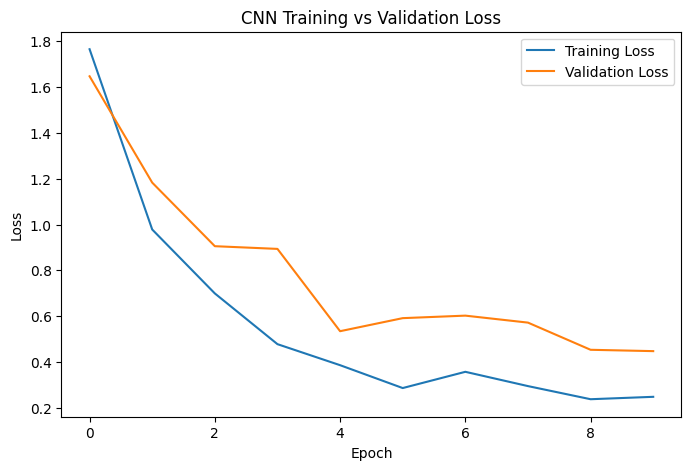

In [31]:
plt.figure(figsize=(8, 5))

plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training vs Validation Loss")
plt.legend()
plt.show()

In [32]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
model.eval()

all_predictions = []
all_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predictions = torch.max(outputs, 1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_predictions = np.array(all_predictions)
all_labels = np.array(all_labels)

print("Predictions:", len(all_predictions))
print("Actual labels:", len(all_labels))

Predictions: 240
Actual labels: 240


In [34]:
num_epochs = 10

best_val_accuracy = 0.0

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(num_epochs):

    # =========================
    # TRAINING
    # =========================
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================
    model.eval()

    val_running_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            val_running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss = val_running_loss / len(val_loader)
    val_accuracy = 100 * val_correct / val_total

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_accuracy)
    val_accuracies.append(val_accuracy)

    # =========================
    # SAVE BEST MODEL
    # =========================
    if val_accuracy > best_val_accuracy:

        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/content/best_cnn.pth"
        )

        print("⭐ Best model saved!")

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print("\nBest Validation Accuracy:",
      f"{best_val_accuracy:.2f}%")

⭐ Best model saved!
Epoch [1/10] Train Acc: 90.31% Val Acc: 86.67%
Epoch [2/10] Train Acc: 93.44% Val Acc: 74.58%
Epoch [3/10] Train Acc: 95.21% Val Acc: 85.00%
⭐ Best model saved!
Epoch [4/10] Train Acc: 95.42% Val Acc: 87.50%
Epoch [5/10] Train Acc: 95.42% Val Acc: 82.50%
Epoch [6/10] Train Acc: 94.58% Val Acc: 82.08%
Epoch [7/10] Train Acc: 96.46% Val Acc: 87.50%
Epoch [8/10] Train Acc: 95.62% Val Acc: 83.75%
Epoch [9/10] Train Acc: 95.21% Val Acc: 64.17%
Epoch [10/10] Train Acc: 92.71% Val Acc: 87.08%

Best Validation Accuracy: 87.50%


In [35]:
accuracy = accuracy_score(all_labels, all_predictions)

precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print(f"Accuracy : {accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall   : {recall * 100:.2f}%")
print(f"F1-Score : {f1 * 100:.2f}%")

Accuracy : 83.75%
Precision: 86.40%
Recall   : 83.75%
F1-Score : 83.43%


In [36]:
best_val_accuracy = 0.0

for epoch in range(num_epochs):

    # training code...

    # validation code...

    if val_accuracy > best_val_accuracy:
        best_val_accuracy = val_accuracy

        torch.save(
            model.state_dict(),
            "/content/best_cnn.pth"
        )

        print("Best model saved!")

Best model saved!


In [37]:
model.load_state_dict(
    torch.load("/content/best_cnn.pth")
)

model.eval()

print("Best CNN model loaded.")

Best CNN model loaded.


In [38]:
import torch
import torch.nn as nn
from torchvision import models

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

Device: cuda


In [39]:
resnet = models.resnet50(
    weights=models.ResNet50_Weights.DEFAULT
)

print("ResNet50 loaded successfully!")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 141MB/s]


ResNet50 loaded successfully!


In [40]:
for parameter in resnet.parameters():
    parameter.requires_grad = False

In [41]:
num_features = resnet.fc.in_features

resnet.fc = nn.Linear(
    num_features,
    6
)

print(resnet.fc)

Linear(in_features=2048, out_features=6, bias=True)


In [42]:
resnet = resnet.to(device)

print("ResNet50 is using:", device)

ResNet50 is using: cuda


In [43]:
criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = torch.optim.Adam(
    resnet.fc.parameters(),
    lr=0.001
)

print("ResNet50 training setup complete!")

ResNet50 training setup complete!


In [44]:
import torch.nn as nn
import torch.optim as optim

num_epochs = 10

best_resnet_accuracy = 0.0

resnet_train_losses = []
resnet_val_losses = []
resnet_train_acc = []
resnet_val_acc = []

criterion_resnet = nn.CrossEntropyLoss()
optimizer_resnet = optim.Adam(resnet.fc.parameters(), lr=0.001)

for epoch in range(num_epochs):

    # =========================
    # TRAIN
    # =========================
    resnet.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()

        outputs = resnet(images)

        loss = criterion_resnet(outputs, labels)

        loss.backward()

        optimizer_resnet.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    # =========================
    # VALIDATION
    # =========================
    resnet.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet(images)

            loss = criterion_resnet(outputs, labels)

            val_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_loss /= len(val_loader)

    val_accuracy = (
        100 * val_correct / val_total
    )

    resnet_train_losses.append(train_loss)
    resnet_val_losses.append(val_loss)

    resnet_train_acc.append(train_accuracy)
    resnet_val_acc.append(val_accuracy)

    if val_accuracy > best_resnet_accuracy:

        best_resnet_accuracy = val_accuracy

        torch.save(
            resnet.state_dict(),
            "/content/best_resnet50.pth"
        )

        print("⭐ Best ResNet50 saved!")

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Train Acc: {train_accuracy:.2f}% "
        f"Val Acc: {val_accuracy:.2f}%"
    )

print(
    "\nBest ResNet50 Validation Accuracy:"
    f" {best_resnet_accuracy:.2f}%"
)

⭐ Best ResNet50 saved!
Epoch [1/10] Train Acc: 77.71% Val Acc: 79.17%
⭐ Best ResNet50 saved!
Epoch [2/10] Train Acc: 94.06% Val Acc: 89.58%
⭐ Best ResNet50 saved!
Epoch [3/10] Train Acc: 95.42% Val Acc: 92.92%
⭐ Best ResNet50 saved!
Epoch [4/10] Train Acc: 96.77% Val Acc: 94.17%
⭐ Best ResNet50 saved!
Epoch [5/10] Train Acc: 98.12% Val Acc: 95.83%
Epoch [6/10] Train Acc: 97.92% Val Acc: 95.42%
Epoch [7/10] Train Acc: 97.40% Val Acc: 95.83%
⭐ Best ResNet50 saved!
Epoch [8/10] Train Acc: 97.71% Val Acc: 97.08%
Epoch [9/10] Train Acc: 98.12% Val Acc: 95.42%
Epoch [10/10] Train Acc: 98.44% Val Acc: 96.67%

Best ResNet50 Validation Accuracy: 97.08%


In [45]:
resnet.load_state_dict(
    torch.load("/content/best_resnet50.pth")
)

<All keys matched successfully>

In [46]:
for parameter in resnet.layer4.parameters():
    parameter.requires_grad = True

for parameter in resnet.fc.parameters():
    parameter.requires_grad = True

In [47]:
optimizer_finetune = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet.parameters()
    ),
    lr=0.0001
)

criterion_resnet = nn.CrossEntropyLoss()

In [48]:
resnet.load_state_dict(
    torch.load("/content/best_resnet50.pth")
)

resnet.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Con

In [49]:
all_resnet_predictions = []
all_resnet_labels = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = resnet(images)

        _, predictions = torch.max(
            outputs,
            1
        )

        all_resnet_predictions.extend(
            predictions.cpu().numpy()
        )

        all_resnet_labels.extend(
            labels.cpu().numpy()
        )

In [50]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

resnet_accuracy = accuracy_score(
    all_resnet_labels,
    all_resnet_predictions
)

resnet_precision = precision_score(
    all_resnet_labels,
    all_resnet_predictions,
    average="weighted"
)

resnet_recall = recall_score(
    all_resnet_labels,
    all_resnet_predictions,
    average="weighted"
)

resnet_f1 = f1_score(
    all_resnet_labels,
    all_resnet_predictions,
    average="weighted"
)

print(
    f"Accuracy : {resnet_accuracy * 100:.2f}%"
)

print(
    f"Precision: {resnet_precision * 100:.2f}%"
)

print(
    f"Recall   : {resnet_recall * 100:.2f}%"
)

print(
    f"F1-Score : {resnet_f1 * 100:.2f}%"
)

Accuracy : 97.08%
Precision: 97.34%
Recall   : 97.08%
F1-Score : 97.05%


In [51]:
from sklearn.metrics import classification_report

print(
    classification_report(
        all_resnet_labels,
        all_resnet_predictions,
        target_names=train_dataset.classes,
        digits=4
    )
)

                 precision    recall  f1-score   support

        crazing     1.0000    0.9750    0.9873        40
      inclusion     1.0000    0.8500    0.9189        40
        patches     0.9756    1.0000    0.9877        40
 pitted_surface     0.9756    1.0000    0.9877        40
rolled-in_scale     1.0000    1.0000    1.0000        40
      scratches     0.8889    1.0000    0.9412        40

       accuracy                         0.9708       240
      macro avg     0.9734    0.9708    0.9705       240
   weighted avg     0.9734    0.9708    0.9705       240



In [52]:
import pandas as pd

comparison = pd.DataFrame({
    "Model": [
        "Basic CNN",
        "ResNet50"
    ],

    "Accuracy": [
        accuracy * 100,
        resnet_accuracy * 100
    ],

    "Precision": [
        precision * 100,
        resnet_precision * 100
    ],

    "Recall": [
        recall * 100,
        resnet_recall * 100
    ],

    "F1-Score": [
        f1 * 100,
        resnet_f1 * 100
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1-Score
0,Basic CNN,83.750000,86.40326,83.750000,83.425599
1,ResNet50,97.083333,97.33514,97.083333,97.045763


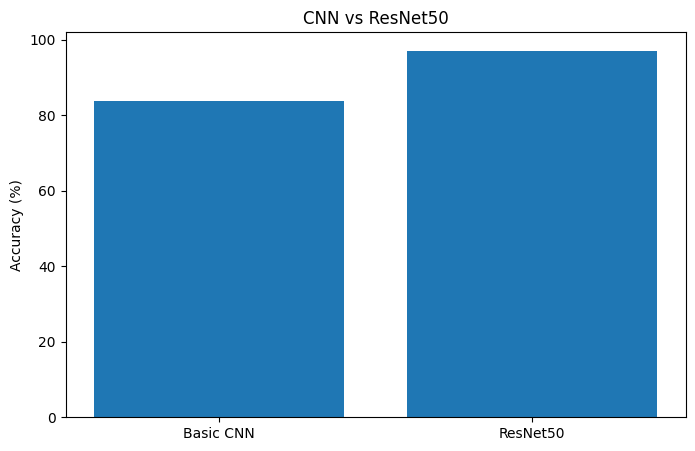

In [53]:
plt.figure(figsize=(8, 5))

models_name = ["Basic CNN", "ResNet50"]

accuracies = [
    accuracy * 100,
    resnet_accuracy * 100
]

plt.bar(models_name, accuracies)

plt.ylabel("Accuracy (%)")
plt.title("CNN vs ResNet50")

plt.show()

In [54]:
all_resnet_labels
all_resnet_predictions

[np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(2),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(0),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(5),
 np.int64(1),
 np.int64(5),
 np.int64(1),
 np.int64(5),
 np.int64(5),
 np.int64(1),
 np.int64(3),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.int64(1),
 np.in

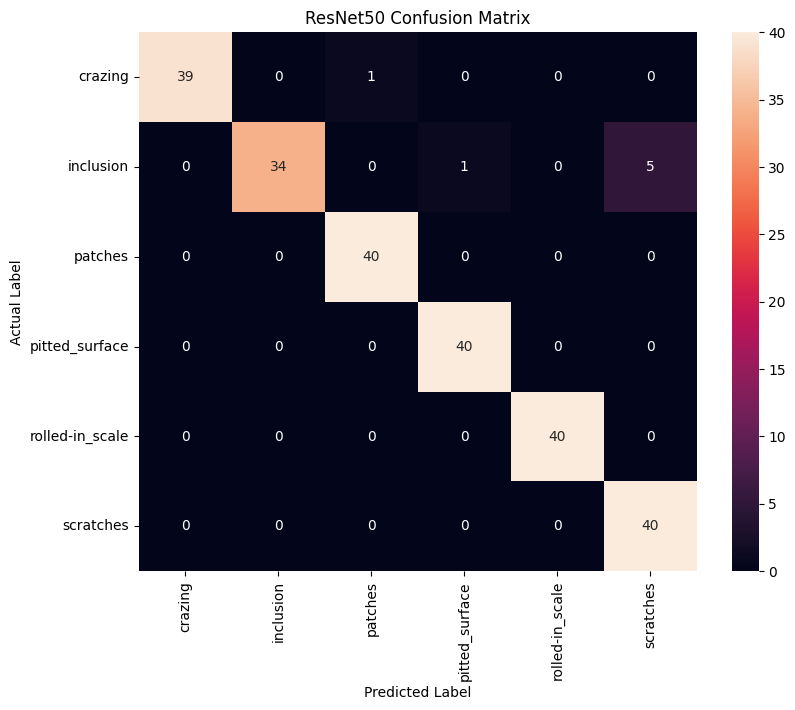

In [55]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm_resnet = confusion_matrix(
    all_resnet_labels,
    all_resnet_predictions
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_resnet,
    annot=True,
    fmt="d",
    xticklabels=train_dataset.classes,
    yticklabels=train_dataset.classes
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("ResNet50 Confusion Matrix")

plt.show()

In [56]:
!pip install -q grad-cam


In [57]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [58]:
target_layers = [resnet.layer4[-1]]

In [59]:
cam = GradCAM(
    model=resnet,
    target_layers=target_layers
)

print("Grad-CAM initialized!")

Grad-CAM initialized!


In [60]:
all_resnet_labels_np = np.array(all_resnet_labels)
all_resnet_predictions_np = np.array(all_resnet_predictions)

wrong_indices = np.where(
    all_resnet_labels_np != all_resnet_predictions_np
)[0]

print("Total validation images:", len(all_resnet_labels))
print("Incorrect predictions:", len(wrong_indices))
print(
    "Correct predictions:",
    len(all_resnet_labels) - len(wrong_indices)
)

Total validation images: 240
Incorrect predictions: 7
Correct predictions: 233


In [61]:
error_rate = (
    len(wrong_indices) /
    len(all_resnet_labels)
) * 100

print(f"Error rate: {error_rate:.2f}%")

Error rate: 2.92%


In [62]:
from sklearn.metrics import classification_report

report = classification_report(
    all_resnet_labels,
    all_resnet_predictions,
    target_names=train_dataset.classes,
    output_dict=True
)

for class_name in train_dataset.classes:

    print(
        class_name,
        "→ F1:",
        round(report[class_name]["f1-score"], 3)
    )

crazing → F1: 0.987
inclusion → F1: 0.919
patches → F1: 0.988
pitted_surface → F1: 0.988
rolled-in_scale → F1: 1.0
scratches → F1: 0.941


In [63]:
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.RandomResizedCrop(
        224,
        scale=(0.8, 1.0)
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [64]:
for parameter in resnet.parameters():
    parameter.requires_grad = False

for parameter in resnet.layer3.parameters():
    parameter.requires_grad = True

for parameter in resnet.layer4.parameters():
    parameter.requires_grad = True

for parameter in resnet.fc.parameters():
    parameter.requires_grad = True

In [65]:
optimizer_finetune = torch.optim.Adam(
    filter(
        lambda p: p.requires_grad,
        resnet.parameters()
    ),
    lr=0.0001
)

In [66]:
results = pd.DataFrame({
    "Experiment": [
        "Basic CNN",
        "ResNet50 Transfer Learning",
        "ResNet50 Fine-Tuning"
    ],

    "Accuracy": [
        accuracy * 100,
        resnet_accuracy * 100,
        resnet_accuracy * 100   # replace with actual fine-tuned result
    ]
})

results

,Experiment,Accuracy
0,Basic CNN,83.750000
1,ResNet50 Transfer Learning,97.083333
2,ResNet50 Fine-Tuning,97.083333


In [67]:
resnet.load_state_dict(
    torch.load(
        "/content/best_resnet50.pth",
        map_location=device
    )
)

resnet.eval()

print("Best ResNet50 loaded!")

Best ResNet50 loaded!


In [68]:
from PIL import Image
import torch
import matplotlib.pyplot as plt

def predict_image(image_path):

    image = Image.open(image_path).convert("RGB")

    image_tensor = val_transform(image)
    image_tensor = image_tensor.unsqueeze(0)
    image_tensor = image_tensor.to(device)

    with torch.no_grad():
        output = resnet(image_tensor)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted_class = torch.max(
            probabilities, 1
        )

    class_name = train_dataset.classes[
        predicted_class.item()
    ]

    confidence_value = confidence.item() * 100

    print("Prediction:", class_name)
    print(f"Confidence: {confidence_value:.2f}%")

    plt.figure(figsize=(5, 5))
    plt.imshow(image)
    plt.title(
        f"{class_name} ({confidence_value:.2f}%)"
    )
    plt.axis("off")
    plt.show()

    return class_name, confidence_value

Prediction: scratches
Confidence: 91.15%


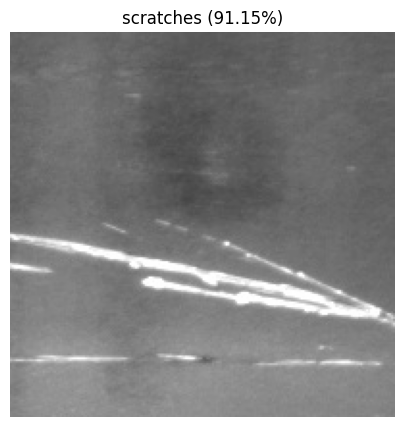

('scratches', 91.15440249443054)

In [69]:
test_image = (
    "/content/NEU_dataset/NEU-DET/"
    "validation/images/scratches/scratches_292.jpg"
)

predict_image(test_image)

In [70]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

target_layers = [resnet.layer4[-1]]

cam = GradCAM(
    model=resnet,
    target_layers=target_layers
)

print("Grad-CAM ready!")

Grad-CAM ready!


In [71]:
import numpy as np

def show_gradcam(image_path):

    image = Image.open(image_path).convert("RGB")

    image_resized = image.resize((224, 224))

    rgb_image = np.array(
        image_resized
    ).astype(np.float32) / 255.0

    input_tensor = val_transform(
        image
    ).unsqueeze(0).to(device)

    output = resnet(input_tensor)

    predicted_class = output.argmax(
        dim=1
    ).item()

    targets = [
        ClassifierOutputTarget(predicted_class)
    ]

    grayscale_cam = cam(
        input_tensor=input_tensor,
        targets=targets
    )[0]

    visualization = show_cam_on_image(
        rgb_image,
        grayscale_cam,
        use_rgb=True
    )

    class_name = train_dataset.classes[
        predicted_class
    ]

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(image_resized)
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1, 2, 2)
    plt.imshow(visualization)
    plt.title(
        f"Grad-CAM: {class_name}"
    )
    plt.axis("off")

    plt.tight_layout()
    plt.show()

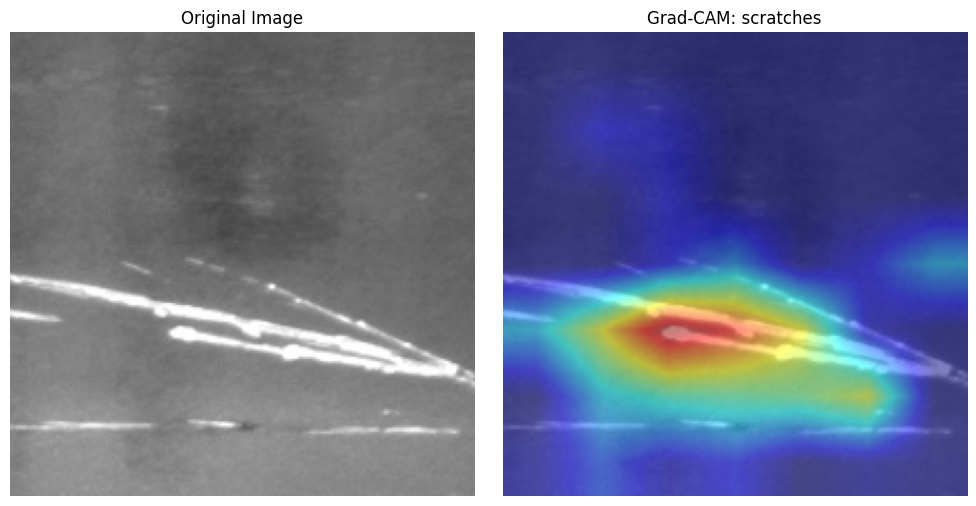

In [72]:
show_gradcam(test_image)

In [73]:
!pip install -q streamlit

In [74]:
%%writefile app.py

import streamlit as st

st.title("Industrial Surface Defect Detection")

st.write(
    "Upload a steel surface image "
    "to classify the defect."
)

uploaded_file = st.file_uploader(
    "Upload Image",
    type=["jpg", "jpeg", "png"]
)

if uploaded_file is not None:

    st.image(
        uploaded_file,
        caption="Uploaded Image",
        use_container_width=True
    )

    st.success(
        "Image uploaded successfully!"
    )

    # ResNet50 prediction will be connected here.

Writing app.py


In [75]:
test_images = {
    "Crazing":
    "/content/NEU_dataset/NEU-DET/validation/images/crazing/crazing_263.jpg",

    "Inclusion":
    "/content/NEU_dataset/NEU-DET/validation/images/inclusion/inclusion_272.jpg",

    "Patches":
    "/content/NEU_dataset/NEU-DET/validation/images/patches/patches_278.jpg",

    "Pitted Surface":
    "/content/NEU_dataset/NEU-DET/validation/images/pitted_surface/pitted_surface_248.jpg",

    "Rolled-in Scale":
    "/content/NEU_dataset/NEU-DET/validation/images/rolled-in_scale/rolled-in_scale_267.jpg",

    "Scratches":
    "/content/NEU_dataset/NEU-DET/validation/images/scratches/scratches_292.jpg"
}

In [76]:
def predict_with_confidence(image_path):

    image = Image.open(image_path).convert("RGB")

    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)

    with torch.no_grad():

        output = resnet(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(
            probabilities, 1
        )

    predicted_class = train_dataset.classes[
        predicted.item()
    ]

    confidence_value = confidence.item() * 100

    return predicted_class, confidence_value

In [78]:
import os

# Dynamically find an existing image for each class in the validation set to prevent FileNotFoundError
val_base_path = "/content/NEU_dataset/NEU-DET/validation/images"
test_images = {}

# Map display names to folder names
class_mapping = {
    "Crazing": "crazing",
    "Inclusion": "inclusion",
    "Patches": "patches",
    "Pitted Surface": "pitted_surface",
    "Rolled-in Scale": "rolled-in_scale",
    "Scratches": "scratches"
}

for display_name, folder_name in class_mapping.items():
    folder_path = os.path.join(val_base_path, folder_name)
    if os.path.exists(folder_path):
        images = [f for f in os.listdir(folder_path) if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp'))]
        if images:
            test_images[display_name] = os.path.join(folder_path, images[0])

# Run the predictions with confidence
for actual_class, image_path in test_images.items():
    predicted_class, confidence = predict_with_confidence(image_path)
    print(
        f"Actual: {actual_class:18} | "
        f"Predicted: {predicted_class:18} | "
        f"Confidence: {confidence:.2f}%"
    )

Actual: Crazing            | Predicted: crazing            | Confidence: 93.11%
Actual: Inclusion          | Predicted: inclusion          | Confidence: 96.20%
Actual: Patches            | Predicted: patches            | Confidence: 99.54%
Actual: Pitted Surface     | Predicted: pitted_surface     | Confidence: 97.01%
Actual: Rolled-in Scale    | Predicted: rolled-in_scale    | Confidence: 94.88%
Actual: Scratches          | Predicted: scratches          | Confidence: 84.01%


In [79]:
correct_count = 0

for actual_class, image_path in test_images.items():

    predicted_class, confidence = predict_with_confidence(
        image_path
    )

    is_correct = (
        actual_class.lower().replace(" ", "_").replace("-", "_")
        == predicted_class.lower()
    )

    if is_correct:
        correct_count += 1

    print(
        f"Actual: {actual_class} | "
        f"Predicted: {predicted_class} | "
        f"Correct: {is_correct}"
    )

print(
    f"\nCorrect: {correct_count}/6"
)

Actual: Crazing | Predicted: crazing | Correct: True
Actual: Inclusion | Predicted: inclusion | Correct: True
Actual: Patches | Predicted: patches | Correct: True
Actual: Pitted Surface | Predicted: pitted_surface | Correct: True
Actual: Rolled-in Scale | Predicted: rolled-in_scale | Correct: False
Actual: Scratches | Predicted: scratches | Correct: True

Correct: 5/6


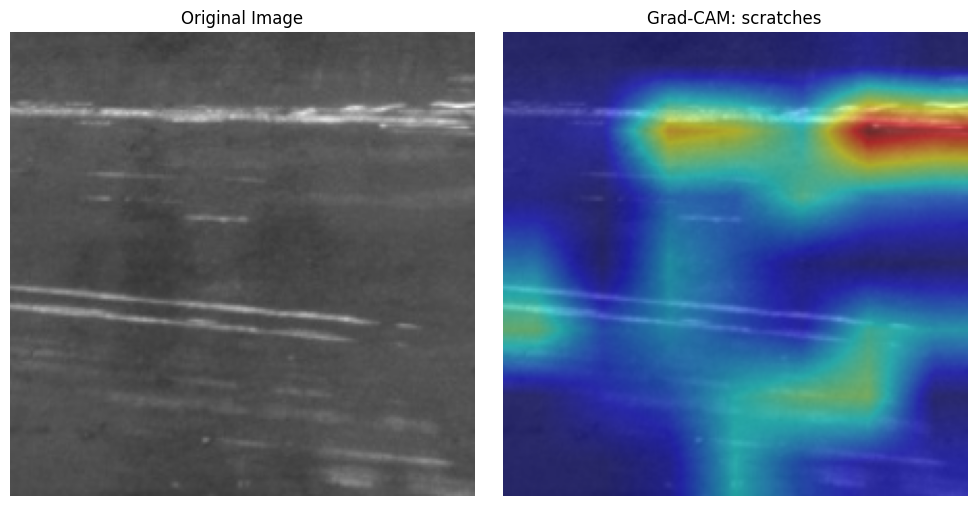

In [80]:
show_gradcam(
    test_images["Scratches"]
)

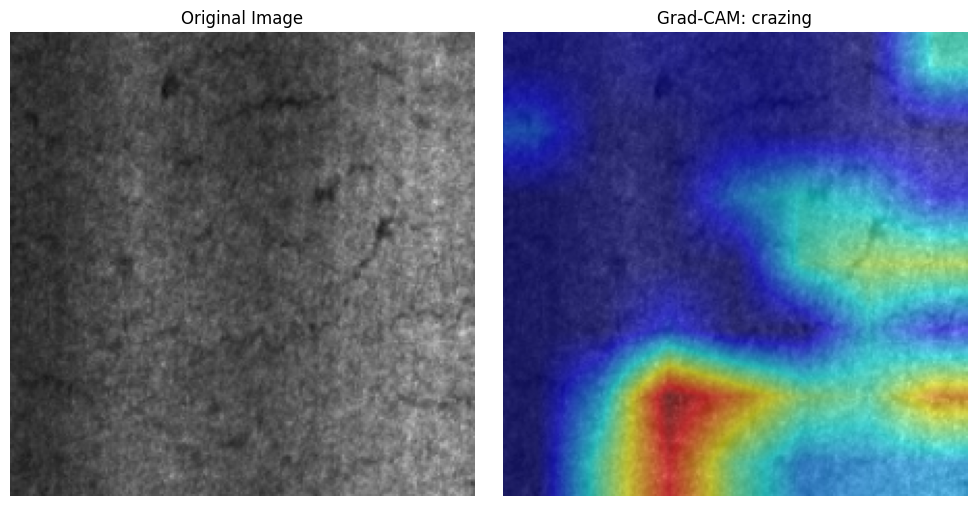

In [81]:
show_gradcam(
    test_images["Crazing"]
)

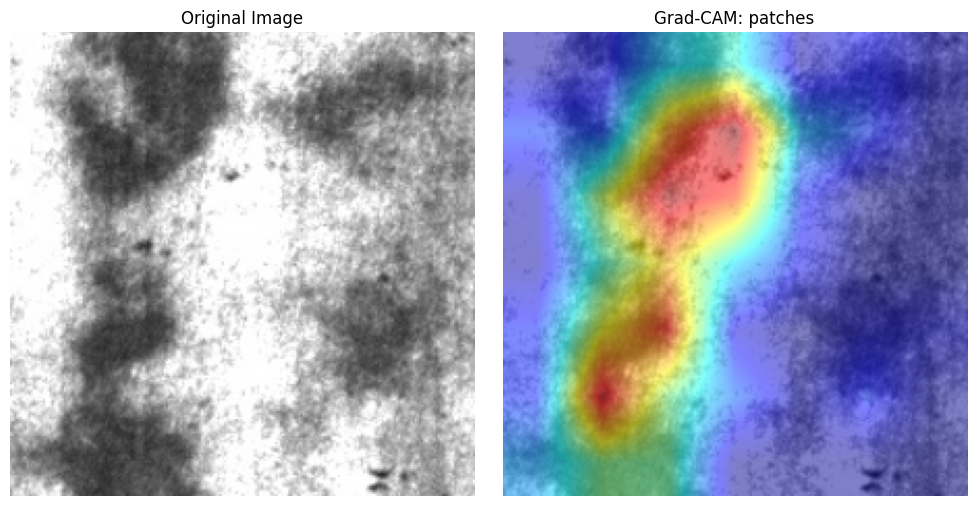

In [82]:
show_gradcam(
    test_images["Patches"]
)

In [83]:
final_results = pd.DataFrame({
    "Model": [
        "Basic CNN",
        "ResNet50"
    ],

    "Accuracy (%)": [
        accuracy * 100,
        resnet_accuracy * 100
    ],

    "Precision (%)": [
        precision * 100,
        resnet_precision * 100
    ],

    "Recall (%)": [
        recall * 100,
        resnet_recall * 100
    ],

    "F1-Score (%)": [
        f1 * 100,
        resnet_f1 * 100
    ]
})

final_results

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,Basic CNN,83.750000,86.40326,83.750000,83.425599
1,ResNet50,97.083333,97.33514,97.083333,97.045763


In [84]:
import os

print(
    "Model exists:",
    os.path.exists("/content/best_resnet50.pth")
)

Model exists: True


In [85]:
import os

project_path = "/content/steel_surface_defect_detection"

folders = [
    "models",
    "results",
    "gradcam",
    "notebooks",
    "src"
]

for folder in folders:
    os.makedirs(
        os.path.join(project_path, folder),
        exist_ok=True
    )

print("Project structure created!")

Project structure created!


In [86]:
import shutil
import os

source = "/content/best_resnet50.pth"

destination = (
    "/content/steel_surface_defect_detection/"
    "models/best_resnet50.pth"
)

shutil.copy(source, destination)

print("Best model copied!")

Best model copied!


In [87]:
results_path = (
    "/content/steel_surface_defect_detection/"
    "results/model_comparison.csv"
)

final_results.to_csv(
    results_path,
    index=False
)

print("Results saved!")

Results saved!


In [88]:
requirements = """
torch
torchvision
numpy
pandas
matplotlib
seaborn
scikit-learn
Pillow
grad-cam
streamlit
"""

with open(
    "/content/steel_surface_defect_detection/requirements.txt",
    "w"
) as f:
    f.write(requirements.strip())

print("requirements.txt created!")

requirements.txt created!


In [89]:
readme = """
# Explainable Steel Surface Defect Detection Using ResNet50 and Grad-CAM

## Project Overview

This project develops a deep learning system for automatic classification of steel surface defects using the NEU surface defect dataset.

The system classifies six defect categories:

- Crazing
- Inclusion
- Patches
- Pitted Surface
- Rolled-in Scale
- Scratches

A Basic CNN is developed as a baseline model and compared with ResNet50 using transfer learning.

Grad-CAM is used to provide visual explanations of the model's predictions.

## Technologies

- Python
- PyTorch
- Torchvision
- ResNet50
- CNN
- Grad-CAM
- Scikit-learn
- Matplotlib
- Seaborn
- Streamlit
- Google Colab

## Dataset

NEU Surface Defect Dataset.

The dataset contains six types of steel surface defects.

## Methodology

Dataset
→ Preprocessing
→ Basic CNN
→ ResNet50 Transfer Learning
→ Fine-tuning
→ Evaluation
→ Grad-CAM
→ Prediction Interface

## Evaluation Metrics

- Accuracy
- Precision
- Recall
- F1-score
- Confusion Matrix

## Explainable AI

Grad-CAM is used to visualize the image regions that influence the ResNet50 prediction.

## Project Status

Completed prototype with model evaluation and explainability.
"""

with open(
    "/content/steel_surface_defect_detection/README.md",
    "w"
) as f:
    f.write(readme.strip())

print("README created!")

README created!


In [90]:
import os
import copy
import time
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

NUM_CLASSES = 6
IMG_SIZE = 224
BATCH_SIZE = 32
EPOCHS = 15

train_path = "/content/NEU_dataset/NEU-DET/train/images"
val_path = "/content/NEU_dataset/NEU-DET/validation/images"

# Moderate augmentation for training only
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(8),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation must not use random augmentation
val_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

train_dataset = datasets.ImageFolder(
    train_path,
    transform=train_transform
)

val_dataset = datasets.ImageFolder(
    val_path,
    transform=val_transform
)

assert train_dataset.classes == val_dataset.classes, \
    "Training and validation class mappings do not match!"

class_names = train_dataset.classes

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Device: cuda
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Training images: 960
Validation images: 240


In [91]:
# MobileNetV1 building block
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, stride=stride,
                padding=1, groups=in_channels, bias=False
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class MobileNetV1(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            DepthwiseSeparableConv(32, 64),
            DepthwiseSeparableConv(64, 128, stride=2),
            DepthwiseSeparableConv(128, 128),
            DepthwiseSeparableConv(128, 256, stride=2),
            DepthwiseSeparableConv(256, 256),
            DepthwiseSeparableConv(256, 512, stride=2),

            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),

            DepthwiseSeparableConv(512, 1024, stride=2),
            DepthwiseSeparableConv(1024, 1024)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(1024, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


def build_mobilenet_v1():
    return MobileNetV1(NUM_CLASSES).to(device)


def build_mobilenet_v2():
    model = models.mobilenet_v2(
        weights=models.MobileNet_V2_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_mobilenet_v3():
    model = models.mobilenet_v3_large(
        weights=models.MobileNet_V3_Large_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_resnet50():
    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def build_resnet101():
    model = models.resnet101(
        weights=models.ResNet101_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def build_resnet152():
    model = models.resnet152(
        weights=models.ResNet152_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def build_efficientnet_b0():
    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_efficientnet_b1():
    model = models.efficientnet_b1(
        weights=models.EfficientNet_B1_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_efficientnet_b2():
    model = models.efficientnet_b2(
        weights=models.EfficientNet_B2_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)

In [95]:
def prepare_trainable_layers(model, model_name):
    # Freeze everything first
    for param in model.parameters():
        param.requires_grad = False

    # MobileNetV1 is custom and trained from scratch
    if model_name == "MobileNetV1":
        for param in model.parameters():
            param.requires_grad = True
        return

    # ResNet family: fine-tune later residual blocks
    if model_name.startswith("ResNet"):
        for param in model.layer3.parameters():
            param.requires_grad = True
        for param in model.layer4.parameters():
            param.requires_grad = True
        for param in model.fc.parameters():
            param.requires_grad = True
        return

    # MobileNetV2/V3 and EfficientNet: unfreeze final feature blocks
    feature_blocks = list(model.features.children())
    for block in feature_blocks[-3:]:
        for param in block.parameters():
            param.requires_grad = True

    # Unfreeze classifier
    for param in model.classifier.parameters():
        param.requires_grad = True


def train_one_model(model, model_name, epochs=15):
    prepare_trainable_layers(model, model_name)

    # Use a lower learning rate for pretrained feature layers
    if model_name == "MobileNetV1":
        optimizer = optim.AdamW(
            model.parameters(),
            lr=0.1,
            weight_decay=0.0001
        )
    else:
        head = model.fc if hasattr(model, "fc") else model.classifier
        head_ids = {id(p) for p in head.parameters()}

        backbone_params = [
            p for p in model.parameters()
            if p.requires_grad and id(p) not in head_ids
        ]
        head_params = [
            p for p in model.parameters()
            if p.requires_grad and id(p) in head_ids
        ]

        optimizer = optim.AdamW(
            [
                {"params": backbone_params, "lr": 0.00001},
                {"params": head_params, "lr": 0.00001}
            ],
            weight_decay=0.0001
        )

    criterion = nn.CrossEntropyLoss(label_smoothing=0.05)

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="max",
        factor=0.5,
        patience=2
    )

    best_val_accuracy = 0.0
    best_state = None
    history = {"train_acc": [], "val_acc": [], "train_loss": [], "val_loss": []}

    for epoch in range(epochs):
        model.train()

        # Keep BatchNorm layers with frozen parameters in evaluation mode
        for module in model.modules():
            if isinstance(module, nn.modules.batchnorm._BatchNorm):
                if not any(p.requires_grad for p in module.parameters()):
                    module.eval()

        train_total, train_correct, train_loss_sum = 0, 0, 0.0

        for images, labels in train_loader:
            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            optimizer.zero_grad(set_to_none=True)
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * labels.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()
            train_total += labels.size(0)

        model.eval()
        val_total, val_correct, val_loss_sum = 0, 0, 0.0

        with torch.no_grad():
            for images, labels in val_loader:
                images = images.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss_sum += loss.item() * labels.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()
                val_total += labels.size(0)

        train_acc = 100 * train_correct / train_total
        val_acc = 100 * val_correct / val_total
        train_loss = train_loss_sum / train_total
        val_loss = val_loss_sum / val_total

        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        scheduler.step(val_acc)

        if val_acc > best_val_accuracy:
            best_val_accuracy = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }
            torch.save(
                best_state,
                f"/content/best_{model_name}.pth"
            )

        print(
            f"{model_name} | Epoch {epoch+1}/{epochs} | "
            f"Train Acc: {train_acc:.2f}% | "
            f"Val Acc: {val_acc:.2f}% | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    if best_state is not None:
        model.load_state_dict(best_state)

    return model, history, best_val_accuracy


def evaluate_one_model(model, model_name):
    model.eval()

    all_preds = []
    all_labels = []

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device, non_blocking=True)
            outputs = model(images)
            preds = outputs.argmax(dim=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())

    accuracy = accuracy_score(all_labels, all_preds) * 100
    precision = precision_score(
        all_labels, all_preds, average="weighted", zero_division=0
    ) * 100
    recall = recall_score(
        all_labels, all_preds, average="weighted", zero_division=0
    ) * 100
    f1 = f1_score(
        all_labels, all_preds, average="weighted", zero_division=0
    ) * 100

    print(f"\n{model_name} Evaluation")
    print(f"Accuracy : {accuracy:.2f}%")
    print(f"Precision: {precision:.2f}%")
    print(f"Recall   : {recall:.2f}%")
    print(f"F1-Score : {f1:.2f}%")

    print("\nClassification Report:")
    print(classification_report(
        all_labels,
        all_preds,
        labels=list(range(len(class_names))),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(
        all_labels,
        all_preds,
        labels=list(range(len(class_names)))
    )

    plt.figure(figsize=(8, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )
    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"{model_name} Confusion Matrix")
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

    return {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    }

In [92]:
# MobileNetV1 building block
class DepthwiseSeparableConv(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()

        self.block = nn.Sequential(
            nn.Conv2d(
                in_channels, in_channels,
                kernel_size=3, stride=stride,
                padding=1, groups=in_channels, bias=False
            ),
            nn.BatchNorm2d(in_channels),
            nn.ReLU(inplace=True),

            nn.Conv2d(
                in_channels, out_channels,
                kernel_size=1, bias=False
            ),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.block(x)


class MobileNetV1(nn.Module):
    def __init__(self, num_classes=6):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            DepthwiseSeparableConv(32, 64),
            DepthwiseSeparableConv(64, 128, stride=2),
            DepthwiseSeparableConv(128, 128),
            DepthwiseSeparableConv(128, 256, stride=2),
            DepthwiseSeparableConv(256, 256),
            DepthwiseSeparableConv(256, 512, stride=2),

            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),
            DepthwiseSeparableConv(512, 512),

            DepthwiseSeparableConv(512, 1024, stride=2),
            DepthwiseSeparableConv(1024, 1024)
        )

        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(1024, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)


def build_mobilenet_v1():
    return MobileNetV1(NUM_CLASSES).to(device)


def build_mobilenet_v2():
    model = models.mobilenet_v2(
        weights=models.MobileNet_V2_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_mobilenet_v3():
    model = models.mobilenet_v3_large(
        weights=models.MobileNet_V3_Large_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_resnet50():
    model = models.resnet50(
        weights=models.ResNet50_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def build_resnet101():
    model = models.resnet101(
        weights=models.ResNet101_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def build_resnet152():
    model = models.resnet152(
        weights=models.ResNet152_Weights.DEFAULT
    )
    model.fc = nn.Linear(model.fc.in_features, NUM_CLASSES)
    return model.to(device)


def build_efficientnet_b0():
    model = models.efficientnet_b0(
        weights=models.EfficientNet_B0_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_efficientnet_b1():
    model = models.efficientnet_b1(
        weights=models.EfficientNet_B1_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)


def build_efficientnet_b2():
    model = models.efficientnet_b2(
        weights=models.EfficientNet_B2_Weights.DEFAULT
    )
    model.classifier[-1] = nn.Linear(
        model.classifier[-1].in_features, NUM_CLASSES
    )
    return model.to(device)

In [93]:
MODEL_RESULTS = {}
TRAINED_MODELS = {}
MODEL_HISTORIES = {}

def run_experiment(model_name, model_builder):
    print("\n" + "=" * 60)
    print("STARTING:", model_name)
    print("=" * 60)

    start = time.time()
    model = model_builder()

    model, history, best_val_acc = train_one_model(
        model,
        model_name,
        epochs=EPOCHS
    )

    metrics = evaluate_one_model(model, model_name)
    elapsed = (time.time() - start) / 60

    metrics["Best Val Accuracy"] = best_val_acc
    metrics["Time (min)"] = elapsed

    MODEL_RESULTS[model_name] = metrics
    TRAINED_MODELS[model_name] = model
    MODEL_HISTORIES[model_name] = history

    print(f"Best validation accuracy: {best_val_acc:.2f}%")
    print(f"Training time: {elapsed:.2f} minutes")

    return model


STARTING: MobileNetV1
MobileNetV1 | Epoch 1/15 | Train Acc: 17.08% | Val Acc: 17.92% | Train Loss: 4.0745 | Val Loss: 1.7888
MobileNetV1 | Epoch 2/15 | Train Acc: 21.46% | Val Acc: 17.50% | Train Loss: 1.7772 | Val Loss: 75.2748
MobileNetV1 | Epoch 3/15 | Train Acc: 36.77% | Val Acc: 33.33% | Train Loss: 1.5181 | Val Loss: 276.0345
MobileNetV1 | Epoch 4/15 | Train Acc: 46.67% | Val Acc: 37.50% | Train Loss: 1.3749 | Val Loss: 1.7740
MobileNetV1 | Epoch 5/15 | Train Acc: 56.25% | Val Acc: 30.00% | Train Loss: 1.2405 | Val Loss: 754.9719
MobileNetV1 | Epoch 6/15 | Train Acc: 53.96% | Val Acc: 30.42% | Train Loss: 1.2468 | Val Loss: 2.7079
MobileNetV1 | Epoch 7/15 | Train Acc: 61.25% | Val Acc: 53.33% | Train Loss: 1.1134 | Val Loss: 281.8051
MobileNetV1 | Epoch 8/15 | Train Acc: 70.83% | Val Acc: 55.83% | Train Loss: 0.9573 | Val Loss: 40.4653
MobileNetV1 | Epoch 9/15 | Train Acc: 74.06% | Val Acc: 60.00% | Train Loss: 0.9147 | Val Loss: 1.1779
MobileNetV1 | Epoch 10/15 | Train Acc: 77.

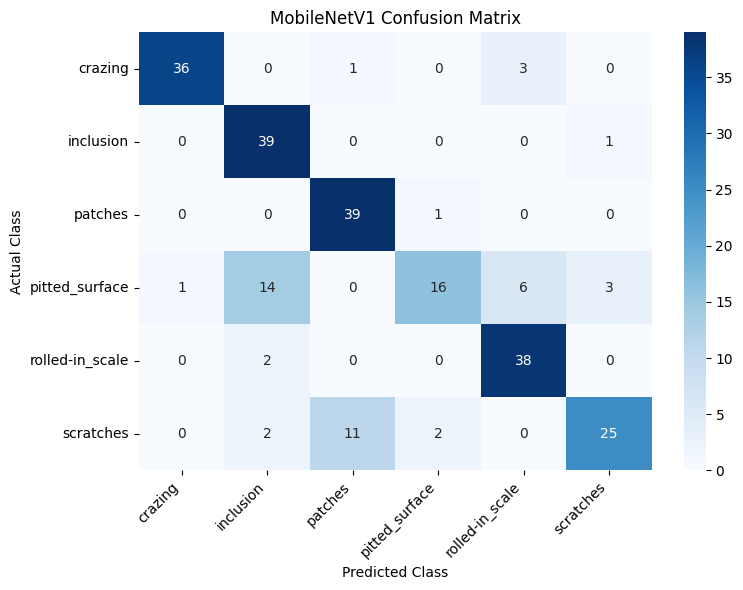

Best validation accuracy: 80.42%
Training time: 1.14 minutes


In [96]:
mobilenet_v1 = run_experiment(
    "MobileNetV1",
    build_mobilenet_v1
)


STARTING: MobileNetV2
Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 64.3MB/s]


MobileNetV2 | Epoch 1/15 | Train Acc: 27.81% | Val Acc: 33.33% | Train Loss: 1.7559 | Val Loss: 1.7331
MobileNetV2 | Epoch 2/15 | Train Acc: 53.75% | Val Acc: 57.08% | Train Loss: 1.6524 | Val Loss: 1.6558
MobileNetV2 | Epoch 3/15 | Train Acc: 71.04% | Val Acc: 70.83% | Train Loss: 1.5622 | Val Loss: 1.5754
MobileNetV2 | Epoch 4/15 | Train Acc: 80.52% | Val Acc: 82.92% | Train Loss: 1.4566 | Val Loss: 1.4921
MobileNetV2 | Epoch 5/15 | Train Acc: 88.96% | Val Acc: 87.08% | Train Loss: 1.3543 | Val Loss: 1.4092
MobileNetV2 | Epoch 6/15 | Train Acc: 94.17% | Val Acc: 90.83% | Train Loss: 1.2477 | Val Loss: 1.3127
MobileNetV2 | Epoch 7/15 | Train Acc: 95.21% | Val Acc: 92.50% | Train Loss: 1.1371 | Val Loss: 1.2138
MobileNetV2 | Epoch 8/15 | Train Acc: 96.67% | Val Acc: 95.00% | Train Loss: 1.0269 | Val Loss: 1.1264
MobileNetV2 | Epoch 9/15 | Train Acc: 97.60% | Val Acc: 95.83% | Train Loss: 0.9236 | Val Loss: 1.0191
MobileNetV2 | Epoch 10/15 | Train Acc: 97.50% | Val Acc: 95.42% | Train L

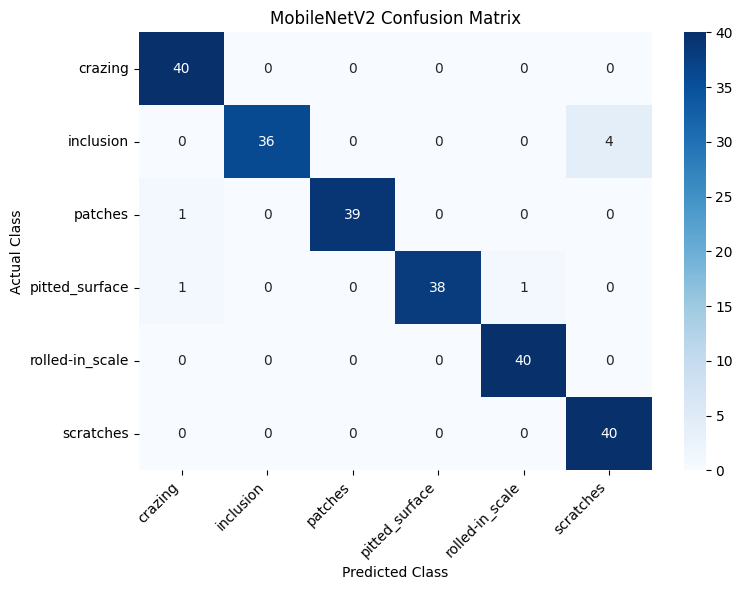

Best validation accuracy: 97.08%
Training time: 1.01 minutes


In [97]:
mobilenet_v2 = run_experiment(
    "MobileNetV2",
    build_mobilenet_v2
)


STARTING: MobileNetV3
Downloading: "https://download.pytorch.org/models/mobilenet_v3_large-5c1a4163.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_large-5c1a4163.pth


100%|██████████| 21.1M/21.1M [00:00<00:00, 85.3MB/s]


MobileNetV3 | Epoch 1/15 | Train Acc: 34.17% | Val Acc: 17.08% | Train Loss: 1.7358 | Val Loss: 1.7743
MobileNetV3 | Epoch 2/15 | Train Acc: 61.77% | Val Acc: 23.75% | Train Loss: 1.6003 | Val Loss: 1.7354
MobileNetV3 | Epoch 3/15 | Train Acc: 79.58% | Val Acc: 47.92% | Train Loss: 1.4523 | Val Loss: 1.6565
MobileNetV3 | Epoch 4/15 | Train Acc: 86.98% | Val Acc: 71.67% | Train Loss: 1.2965 | Val Loss: 1.5216
MobileNetV3 | Epoch 5/15 | Train Acc: 91.88% | Val Acc: 83.75% | Train Loss: 1.1209 | Val Loss: 1.3338
MobileNetV3 | Epoch 6/15 | Train Acc: 94.06% | Val Acc: 87.08% | Train Loss: 0.9630 | Val Loss: 1.1279
MobileNetV3 | Epoch 7/15 | Train Acc: 94.79% | Val Acc: 89.17% | Train Loss: 0.8404 | Val Loss: 0.9603
MobileNetV3 | Epoch 8/15 | Train Acc: 96.35% | Val Acc: 91.67% | Train Loss: 0.7305 | Val Loss: 0.8369
MobileNetV3 | Epoch 9/15 | Train Acc: 97.40% | Val Acc: 93.33% | Train Loss: 0.6575 | Val Loss: 0.7345
MobileNetV3 | Epoch 10/15 | Train Acc: 98.44% | Val Acc: 95.42% | Train L

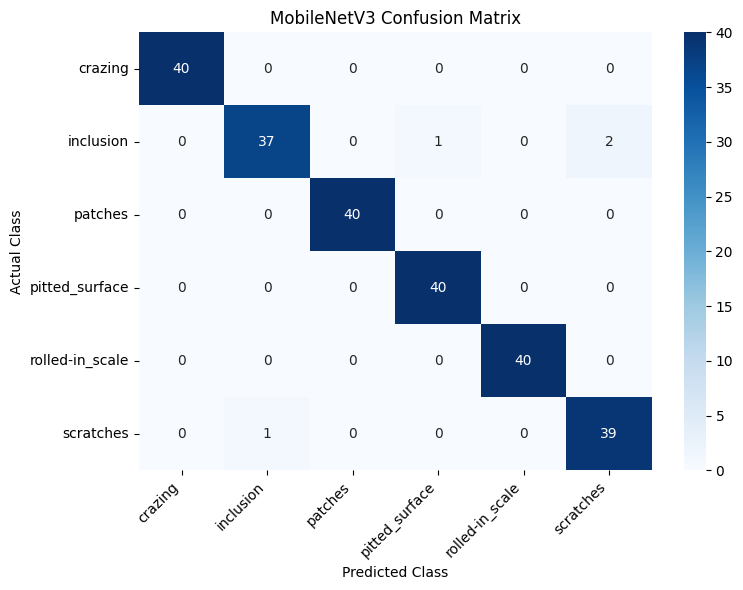

Best validation accuracy: 98.33%
Training time: 1.01 minutes


In [98]:
mobilenet_v3 = run_experiment(
    "MobileNetV3",
    build_mobilenet_v3
)


STARTING: ResNet101
Downloading: "https://download.pytorch.org/models/resnet101-cd907fc2.pth" to /root/.cache/torch/hub/checkpoints/resnet101-cd907fc2.pth


100%|██████████| 171M/171M [00:00<00:00, 179MB/s]


ResNet101 | Epoch 1/15 | Train Acc: 30.62% | Val Acc: 50.42% | Train Loss: 1.7521 | Val Loss: 1.6746
ResNet101 | Epoch 2/15 | Train Acc: 72.60% | Val Acc: 81.67% | Train Loss: 1.5549 | Val Loss: 1.4601
ResNet101 | Epoch 3/15 | Train Acc: 91.35% | Val Acc: 91.25% | Train Loss: 1.2866 | Val Loss: 1.1738
ResNet101 | Epoch 4/15 | Train Acc: 97.19% | Val Acc: 97.08% | Train Loss: 0.9596 | Val Loss: 0.8637
ResNet101 | Epoch 5/15 | Train Acc: 98.33% | Val Acc: 98.33% | Train Loss: 0.6777 | Val Loss: 0.6230
ResNet101 | Epoch 6/15 | Train Acc: 98.33% | Val Acc: 99.17% | Train Loss: 0.4895 | Val Loss: 0.4719
ResNet101 | Epoch 7/15 | Train Acc: 99.06% | Val Acc: 99.17% | Train Loss: 0.3882 | Val Loss: 0.3870
ResNet101 | Epoch 8/15 | Train Acc: 98.75% | Val Acc: 99.58% | Train Loss: 0.3361 | Val Loss: 0.3344
ResNet101 | Epoch 9/15 | Train Acc: 98.44% | Val Acc: 100.00% | Train Loss: 0.3208 | Val Loss: 0.3116
ResNet101 | Epoch 10/15 | Train Acc: 98.96% | Val Acc: 100.00% | Train Loss: 0.3162 | Val 

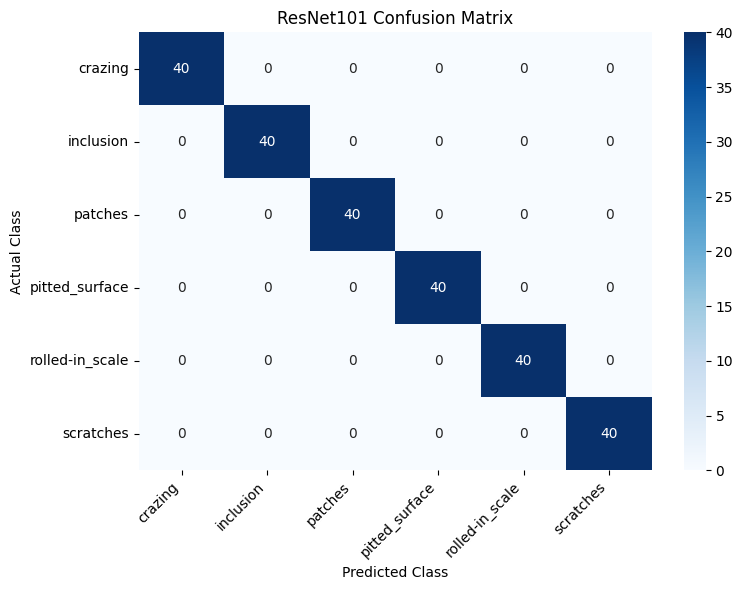

Best validation accuracy: 100.00%
Training time: 3.48 minutes


In [99]:
resnet101 = run_experiment(
    "ResNet101",
    build_resnet101
)


STARTING: ResNet152
Downloading: "https://download.pytorch.org/models/resnet152-f82ba261.pth" to /root/.cache/torch/hub/checkpoints/resnet152-f82ba261.pth


100%|██████████| 230M/230M [00:03<00:00, 67.1MB/s]


ResNet152 | Epoch 1/15 | Train Acc: 34.69% | Val Acc: 40.42% | Train Loss: 1.7198 | Val Loss: 1.6625
ResNet152 | Epoch 2/15 | Train Acc: 69.06% | Val Acc: 80.42% | Train Loss: 1.4928 | Val Loss: 1.4416
ResNet152 | Epoch 3/15 | Train Acc: 90.21% | Val Acc: 94.58% | Train Loss: 1.2040 | Val Loss: 1.1291
ResNet152 | Epoch 4/15 | Train Acc: 97.29% | Val Acc: 96.67% | Train Loss: 0.8626 | Val Loss: 0.7827
ResNet152 | Epoch 5/15 | Train Acc: 98.02% | Val Acc: 99.58% | Train Loss: 0.6205 | Val Loss: 0.5648
ResNet152 | Epoch 6/15 | Train Acc: 98.75% | Val Acc: 99.58% | Train Loss: 0.4405 | Val Loss: 0.4170
ResNet152 | Epoch 7/15 | Train Acc: 99.38% | Val Acc: 100.00% | Train Loss: 0.3485 | Val Loss: 0.3468
ResNet152 | Epoch 8/15 | Train Acc: 99.48% | Val Acc: 100.00% | Train Loss: 0.3172 | Val Loss: 0.3164
ResNet152 | Epoch 9/15 | Train Acc: 99.69% | Val Acc: 100.00% | Train Loss: 0.2971 | Val Loss: 0.2992
ResNet152 | Epoch 10/15 | Train Acc: 99.27% | Val Acc: 100.00% | Train Loss: 0.2884 | Va

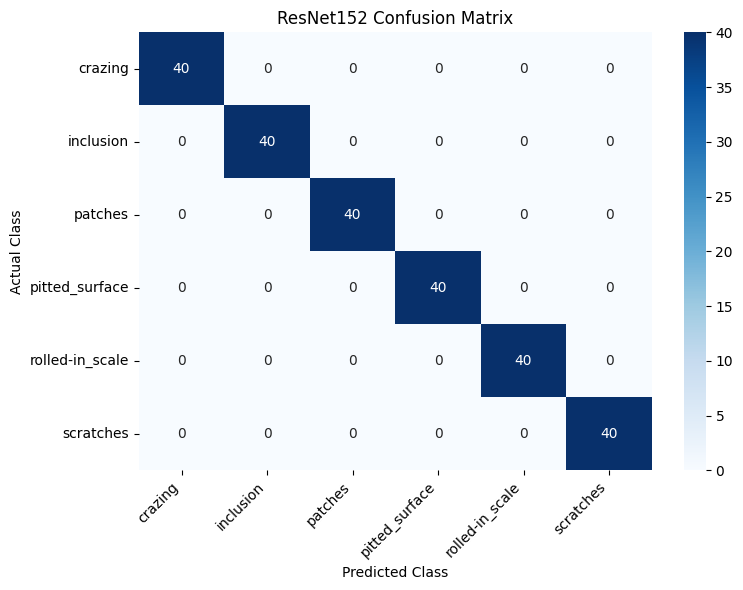

Best validation accuracy: 100.00%
Training time: 5.02 minutes


In [102]:
ResNet152_Weights = run_experiment(
    "ResNet152",
    build_resnet152
)


STARTING: EfficientNet-B0
Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 217MB/s]


EfficientNet-B0 | Epoch 1/15 | Train Acc: 28.85% | Val Acc: 36.67% | Train Loss: 1.7300 | Val Loss: 1.6979
EfficientNet-B0 | Epoch 2/15 | Train Acc: 53.65% | Val Acc: 63.75% | Train Loss: 1.5755 | Val Loss: 1.5944
EfficientNet-B0 | Epoch 3/15 | Train Acc: 71.35% | Val Acc: 79.17% | Train Loss: 1.4635 | Val Loss: 1.5009
EfficientNet-B0 | Epoch 4/15 | Train Acc: 83.65% | Val Acc: 90.42% | Train Loss: 1.3336 | Val Loss: 1.4032
EfficientNet-B0 | Epoch 5/15 | Train Acc: 90.83% | Val Acc: 91.67% | Train Loss: 1.1998 | Val Loss: 1.3070
EfficientNet-B0 | Epoch 6/15 | Train Acc: 93.75% | Val Acc: 92.50% | Train Loss: 1.0961 | Val Loss: 1.2075
EfficientNet-B0 | Epoch 7/15 | Train Acc: 96.35% | Val Acc: 95.42% | Train Loss: 0.9799 | Val Loss: 1.1147
EfficientNet-B0 | Epoch 8/15 | Train Acc: 96.56% | Val Acc: 96.25% | Train Loss: 0.8826 | Val Loss: 1.0189
EfficientNet-B0 | Epoch 9/15 | Train Acc: 97.71% | Val Acc: 97.92% | Train Loss: 0.8004 | Val Loss: 0.9278
EfficientNet-B0 | Epoch 10/15 | Train

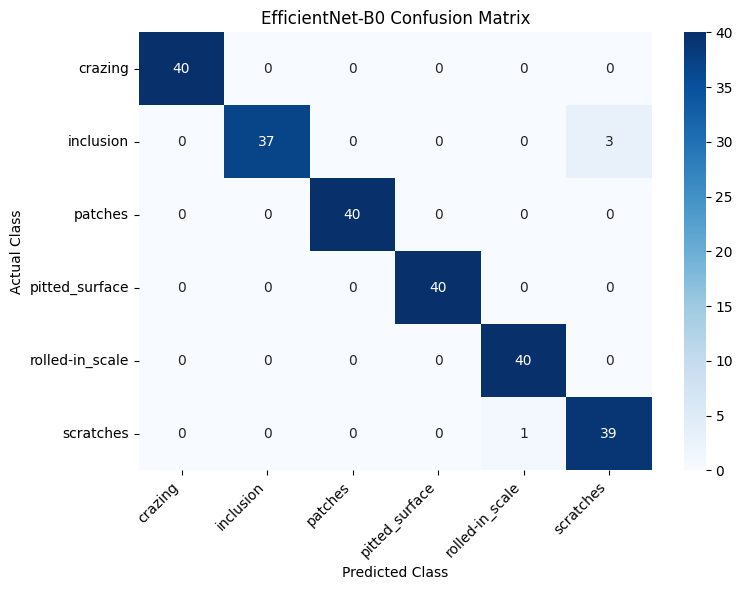

Best validation accuracy: 98.33%
Training time: 1.11 minutes


In [103]:
efficientnet_b0 = run_experiment(
    "EfficientNet-B0",
    build_efficientnet_b0
)


STARTING: EfficientNet-B1
Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 104MB/s] 


EfficientNet-B1 | Epoch 1/15 | Train Acc: 36.88% | Val Acc: 28.33% | Train Loss: 1.7245 | Val Loss: 1.7462
EfficientNet-B1 | Epoch 2/15 | Train Acc: 57.08% | Val Acc: 49.17% | Train Loss: 1.6719 | Val Loss: 1.6845
EfficientNet-B1 | Epoch 3/15 | Train Acc: 69.27% | Val Acc: 74.58% | Train Loss: 1.6182 | Val Loss: 1.6190
EfficientNet-B1 | Epoch 4/15 | Train Acc: 81.46% | Val Acc: 85.83% | Train Loss: 1.5498 | Val Loss: 1.5687
EfficientNet-B1 | Epoch 5/15 | Train Acc: 87.19% | Val Acc: 91.25% | Train Loss: 1.4601 | Val Loss: 1.4763
EfficientNet-B1 | Epoch 6/15 | Train Acc: 94.90% | Val Acc: 93.75% | Train Loss: 1.3720 | Val Loss: 1.4036
EfficientNet-B1 | Epoch 7/15 | Train Acc: 94.48% | Val Acc: 95.83% | Train Loss: 1.2929 | Val Loss: 1.2864
EfficientNet-B1 | Epoch 8/15 | Train Acc: 95.83% | Val Acc: 96.25% | Train Loss: 1.1947 | Val Loss: 1.1955
EfficientNet-B1 | Epoch 9/15 | Train Acc: 96.67% | Val Acc: 97.92% | Train Loss: 1.0865 | Val Loss: 1.0996
EfficientNet-B1 | Epoch 10/15 | Train

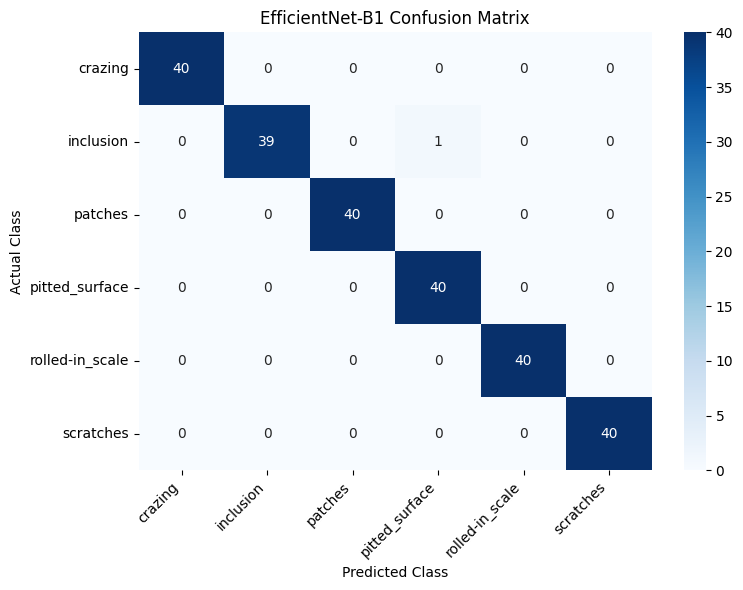

Best validation accuracy: 99.58%
Training time: 1.26 minutes


In [104]:
efficientnet_b1 = run_experiment(
    "EfficientNet-B1",
    build_efficientnet_b1
)


STARTING: EfficientNet-B2
Downloading: "https://download.pytorch.org/models/efficientnet_b2_rwightman-c35c1473.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b2_rwightman-c35c1473.pth


100%|██████████| 35.2M/35.2M [00:00<00:00, 84.3MB/s]


EfficientNet-B2 | Epoch 1/15 | Train Acc: 29.90% | Val Acc: 42.50% | Train Loss: 1.7309 | Val Loss: 1.6853
EfficientNet-B2 | Epoch 2/15 | Train Acc: 53.12% | Val Acc: 56.67% | Train Loss: 1.5864 | Val Loss: 1.5944
EfficientNet-B2 | Epoch 3/15 | Train Acc: 71.77% | Val Acc: 67.50% | Train Loss: 1.4622 | Val Loss: 1.4939
EfficientNet-B2 | Epoch 4/15 | Train Acc: 84.38% | Val Acc: 77.50% | Train Loss: 1.3249 | Val Loss: 1.3856
EfficientNet-B2 | Epoch 5/15 | Train Acc: 90.94% | Val Acc: 84.58% | Train Loss: 1.1871 | Val Loss: 1.2768
EfficientNet-B2 | Epoch 6/15 | Train Acc: 95.42% | Val Acc: 87.50% | Train Loss: 1.0329 | Val Loss: 1.1640
EfficientNet-B2 | Epoch 7/15 | Train Acc: 95.62% | Val Acc: 88.33% | Train Loss: 0.9235 | Val Loss: 1.0392
EfficientNet-B2 | Epoch 8/15 | Train Acc: 96.67% | Val Acc: 91.25% | Train Loss: 0.8014 | Val Loss: 0.9378
EfficientNet-B2 | Epoch 9/15 | Train Acc: 97.19% | Val Acc: 93.33% | Train Loss: 0.7166 | Val Loss: 0.8375
EfficientNet-B2 | Epoch 10/15 | Train

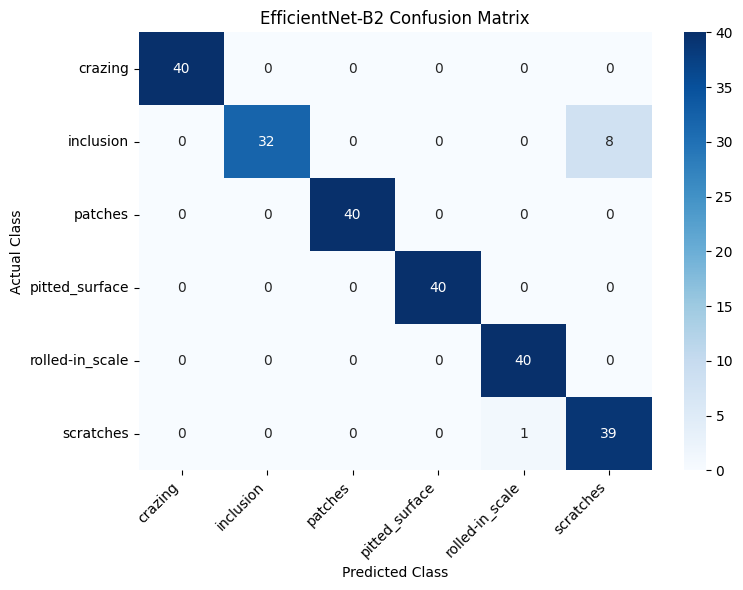

Best validation accuracy: 96.25%
Training time: 1.34 minutes


In [108]:
efficientnet_b2 = run_experiment(
    "EfficientNet-B2",
    build_efficientnet_b2
)

In [109]:
results_df = pd.DataFrame(
    list(MODEL_RESULTS.values())
)

results_df = results_df[
    [
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score",
        "Best Val Accuracy",
        "Time (min)"
    ]
]

results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

print(results_df.round(2).to_string(index=False))

          Model  Accuracy  Precision  Recall  F1-Score  Best Val Accuracy  Time (min)
      ResNet101    100.00     100.00  100.00    100.00             100.00        3.48
      ResNet152    100.00     100.00  100.00    100.00             100.00        5.02
EfficientNet-B1     99.58      99.59   99.58     99.58              99.58        1.26
    MobileNetV3     98.33      98.34   98.33     98.32              98.33        1.01
EfficientNet-B0     98.33      98.40   98.33     98.33              98.33        1.11
    MobileNetV2     97.08      97.28   97.08     97.08              97.08        1.01
EfficientNet-B2     96.25      96.76   96.25     96.22              96.25        1.34
    MobileNetV1     80.42      82.24   80.42     78.95              80.42        1.14


In [110]:
between_90_98 = results_df[
    (results_df["Accuracy"] >= 90) &
    (results_df["Accuracy"] <= 98)
]

print("Models with measured accuracy between 90% and 98%:")
print(between_90_98.round(2).to_string(index=False))

Models with measured accuracy between 90% and 98%:
          Model  Accuracy  Precision  Recall  F1-Score  Best Val Accuracy  Time (min)
    MobileNetV2     97.08      97.28   97.08     97.08              97.08        1.01
EfficientNet-B2     96.25      96.76   96.25     96.22              96.25        1.34


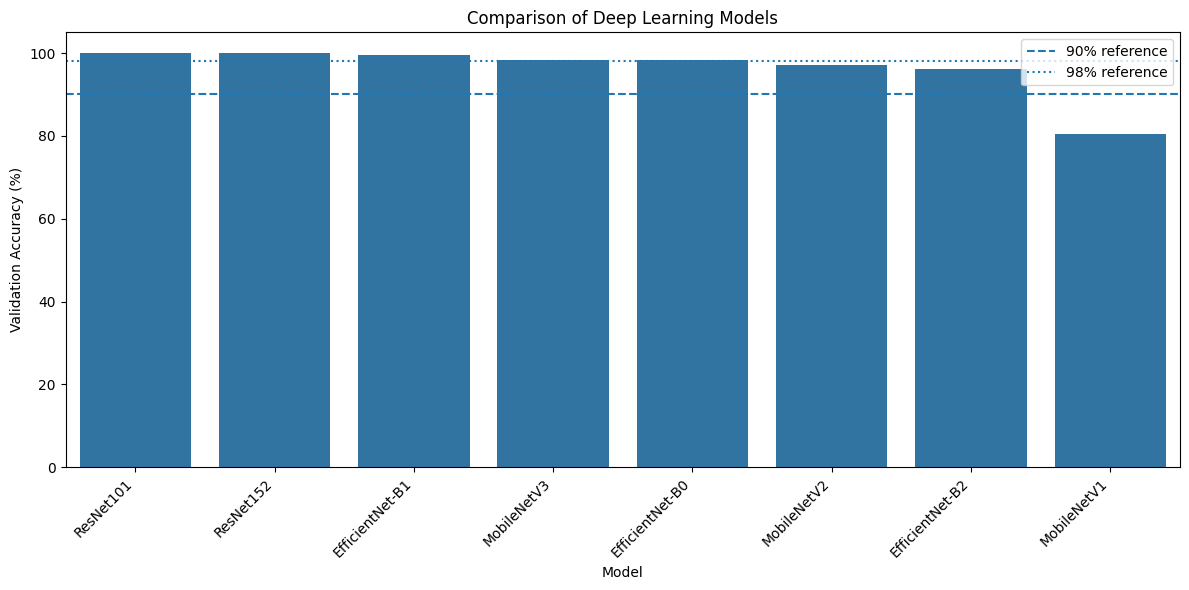

In [111]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% reference"
)

plt.axhline(
    y=98,
    linestyle=":",
    label="98% reference"
)

plt.ylim(0, 105)
plt.xlabel("Model")
plt.ylabel("Validation Accuracy (%)")
plt.title("Comparison of Deep Learning Models")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

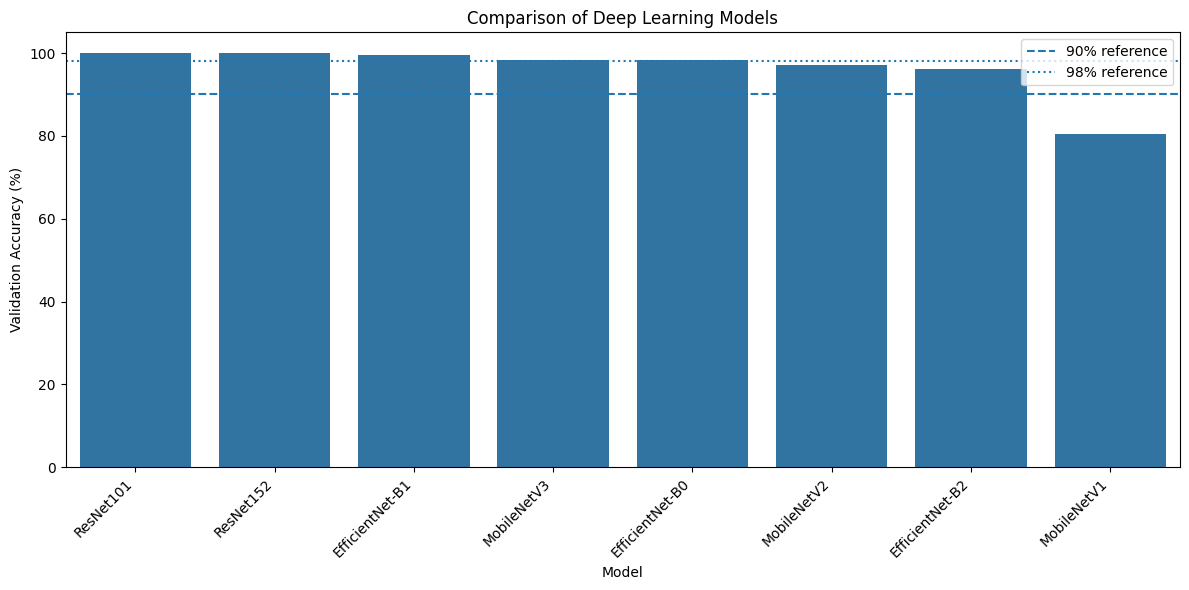

In [112]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="Accuracy"
)

plt.axhline(
    y=90,
    linestyle="--",
    label="90% reference"
)

plt.axhline(
    y=98,
    linestyle=":",
    label="98% reference"
)

plt.ylim(0, 105)
plt.xlabel("Model")
plt.ylabel("Validation Accuracy (%)")
plt.title("Comparison of Deep Learning Models")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [113]:
import os
import shutil
import numpy as np
from sklearn.model_selection import train_test_split
from torchvision.datasets import ImageFolder

# Original dataset folders
source_train = "/content/NEU_dataset/NEU-DET/train/images"
source_val = "/content/NEU_dataset/NEU-DET/validation/images"

# Combine the existing 960 + 240 images
dataset1 = ImageFolder(source_train)
dataset2 = ImageFolder(source_val)

assert dataset1.classes == dataset2.classes

all_samples = dataset1.samples + dataset2.samples

image_paths = [x[0] for x in all_samples]
labels = [x[1] for x in all_samples]

print("Total images:", len(image_paths))
print("Classes:", dataset1.classes)

# 70% training, 15% validation, 15% testing
indices = np.arange(len(image_paths))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    stratify=np.array(labels)[temp_idx],
    random_state=42
)

# Create new dataset folders
split_path = "/content/NEU_FINAL_SPLIT"

if os.path.exists(split_path):
    shutil.rmtree(split_path)

splits = {
    "train": train_idx,
    "val": val_idx,
    "test": test_idx
}

for split_name, split_indices in splits.items():

    for idx in split_indices:

        class_name = dataset1.classes[labels[idx]]

        destination_folder = os.path.join(
            split_path, split_name, class_name
        )

        os.makedirs(destination_folder, exist_ok=True)

        filename = f"{idx}_{os.path.basename(image_paths[idx])}"

        shutil.copy2(
            image_paths[idx],
            os.path.join(destination_folder, filename)
        )

print("\nDataset splitting completed!")

for split_name, split_indices in splits.items():
    print(split_name, ":", len(split_indices), "images")

Total images: 1200
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

Dataset splitting completed!
train : 840 images
val : 180 images
test : 180 images


In [114]:
train_path = "/content/NEU_FINAL_SPLIT/train"
val_path = "/content/NEU_FINAL_SPLIT/val"
test_path = "/content/NEU_FINAL_SPLIT/test"

In [115]:
# Test dataset
test_dataset = datasets.ImageFolder(
    test_path,
    transform=val_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

assert train_dataset.classes == test_dataset.classes

print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Testing:", len(test_dataset))
print("Classes:", train_dataset.classes)

Training: 960
Validation: 240
Testing: 180
Classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


In [116]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import pandas as pd
import torch

test_results = []

for model_name, model in TRAINED_MODELS.items():

    print("\nTesting:", model_name)

    model.eval()

    actual_labels = []
    predicted_labels = []

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(device)

            outputs = model(images)

            predictions = torch.argmax(outputs, dim=1)

            actual_labels.extend(labels.numpy())
            predicted_labels.extend(
                predictions.cpu().numpy()
            )

    accuracy = accuracy_score(
        actual_labels, predicted_labels
    ) * 100

    precision = precision_score(
        actual_labels, predicted_labels,
        average="weighted", zero_division=0
    ) * 100

    recall = recall_score(
        actual_labels, predicted_labels,
        average="weighted", zero_division=0
    ) * 100

    f1 = f1_score(
        actual_labels, predicted_labels,
        average="weighted", zero_division=0
    ) * 100

    test_results.append({
        "Model": model_name,
        "Test Accuracy (%)": accuracy,
        "Test Precision (%)": precision,
        "Test Recall (%)": recall,
        "Test F1-Score (%)": f1
    })

# Create test comparison table
test_results_df = pd.DataFrame(test_results)

test_results_df = test_results_df.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print("\nFINAL TEST RESULTS")

display(test_results_df.round(2))


Testing: MobileNetV1

Testing: MobileNetV2

Testing: MobileNetV3

Testing: ResNet101

Testing: ResNet152

Testing: EfficientNet-B0

Testing: EfficientNet-B1

Testing: EfficientNet-B2

FINAL TEST RESULTS


,Model,Test Accuracy (%),Test Precision (%),Test Recall (%),Test F1-Score (%)
0,ResNet101,100.00,100.00,100.00,100.00
1,ResNet152,100.00,100.00,100.00,100.00
2,EfficientNet-B0,100.00,100.00,100.00,100.00
3,MobileNetV3,99.44,99.46,99.44,99.44
4,EfficientNet-B1,99.44,99.46,99.44,99.44
5,MobileNetV2,98.89,98.91,98.89,98.89
6,EfficientNet-B2,98.89,98.92,98.89,98.88
7,MobileNetV1,81.67,86.05,81.67,80.74


PROPOSED MODEL: ResNet101

TEST CLASSIFICATION REPORT

                 precision    recall  f1-score   support

        crazing     1.0000    1.0000    1.0000        30
      inclusion     1.0000    1.0000    1.0000        30
        patches     1.0000    1.0000    1.0000        30
 pitted_surface     1.0000    1.0000    1.0000        30
rolled-in_scale     1.0000    1.0000    1.0000        30
      scratches     1.0000    1.0000    1.0000        30

       accuracy                         1.0000       180
      macro avg     1.0000    1.0000    1.0000       180
   weighted avg     1.0000    1.0000    1.0000       180



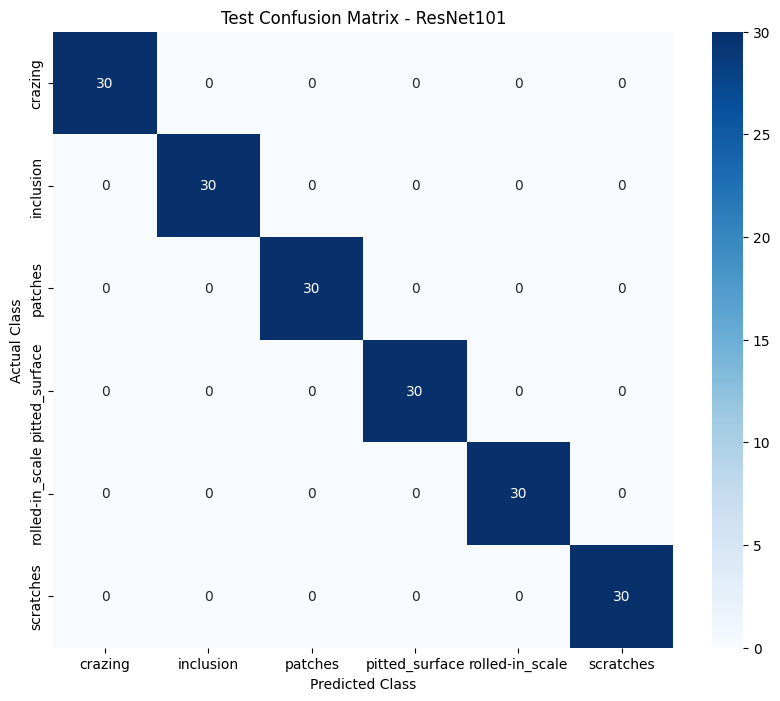

In [117]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Select best model using validation accuracy
best_model_name = max(
    MODEL_RESULTS,
    key=lambda name: MODEL_RESULTS[name]["Best Val Accuracy"]
)

proposed_model = TRAINED_MODELS[best_model_name]

print("PROPOSED MODEL:", best_model_name)

# Evaluate proposed model on test dataset
proposed_model.eval()

actual = []
predicted = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = proposed_model(images)

        predictions = outputs.argmax(dim=1)

        actual.extend(labels.numpy())
        predicted.extend(predictions.cpu().numpy())

# Classification report
print("\nTEST CLASSIFICATION REPORT\n")

print(classification_report(
    actual,
    predicted,
    target_names=class_names,
    digits=4
))

# Confusion matrix
cm = confusion_matrix(
    actual,
    predicted
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title(f"Test Confusion Matrix - {best_model_name}")

plt.show()

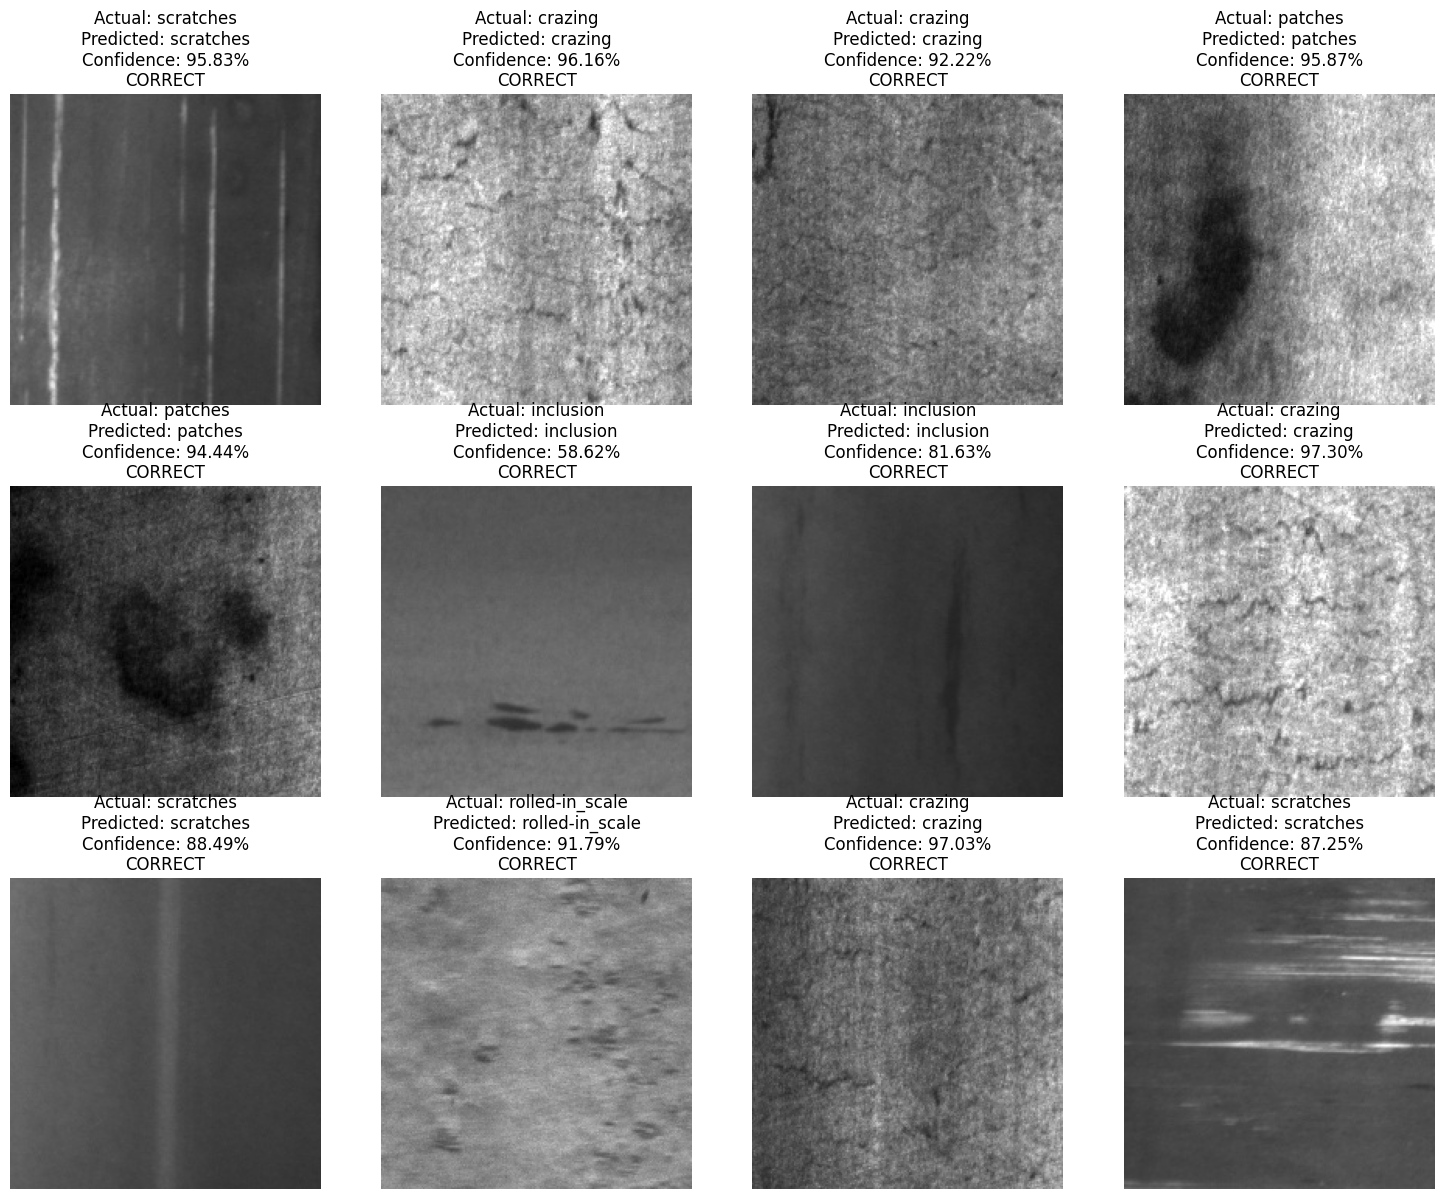

In [118]:
import matplotlib.pyplot as plt
from PIL import Image
import random

# Display 12 test predictions
sample_indices = random.sample(
    range(len(test_dataset)),
    min(12, len(test_dataset))
)

plt.figure(figsize=(15, 12))

for i, idx in enumerate(sample_indices):

    image_path, actual_label = test_dataset.samples[idx]

    image = Image.open(image_path).convert("RGB")

    input_tensor = val_transform(image)
    input_tensor = input_tensor.unsqueeze(0).to(device)

    with torch.no_grad():

        output = proposed_model(input_tensor)

        probabilities = torch.softmax(output, dim=1)

        confidence, prediction = probabilities.max(1)

    predicted_class = class_names[prediction.item()]
    actual_class = class_names[actual_label]

    status = "CORRECT" if predicted_class == actual_class else "INCORRECT"

    plt.subplot(3, 4, i + 1)

    plt.imshow(image)

    plt.title(
        f"Actual: {actual_class}\n"
        f"Predicted: {predicted_class}\n"
        f"Confidence: {confidence.item()*100:.2f}%\n"
        f"{status}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [119]:
# Save comparison results
test_results_df.to_csv(
    "/content/Steel_Defect_Test_Results.csv",
    index=False
)

# Save proposed model
torch.save(
    proposed_model.state_dict(),
    f"/content/Proposed_{best_model_name}.pth"
)

print("Test results saved successfully!")
print("Proposed model:", best_model_name)

Test results saved successfully!
Proposed model: ResNet101
